# LAB12 — Stage 07: Evidence-Based Feature Engineering, Feature Selection & Ablation Studies

## Genel Bakış

Bu notebook, **LAB12 — Freight Cost Prediction PoC** projesinin yedinci aşamasıdır.

Stage 06, 5 kontrollü deneyle (EXP-01...EXP-05) preprocessing adaylarını belirledi. Bu
notebook'ta amaç **yeni feature'lar bulmak değil** -- business-semantically valid,
prediction-time available, istatistiksel olarak savunulabilir ve deneysel olarak faydalı
feature set'lerini belirlemektir.

**Mandatory Engineering Workflow:**

```
Business Hypothesis -> Feature Definition -> Availability Audit -> Leakage Audit
  -> Statistical Diagnostics -> Controlled CV Experiment -> Ablation -> Stability Analysis
  -> Engineering Decision
```

## Learning Objectives

1. Feature Engineering ve Feature Selection farkını açıklayabilmek.
2. Feature availability ile predictive usefulness farkını anlayabilmek.
3. Shipment-level feature design gerçekleştirebilmek.
4. Feature leakage tespit edebilmek.
5. Filter / Embedded / Wrapper feature selection yöntemlerini karşılaştırabilmek.
6. Feature-group ablation uygulayabilmek.
7. Permutation Importance ve feature stability ölçebilmek.
8. Feature count ile prediction error arasındaki trade-off'u değerlendirebilmek.

## Bu Notebook'ta Yapılmayacaklar

- Stage 05 split/CV protokolü değiştirilmeyecek.
- 2014 Validation / 2015 Protected Test target değerleri **hiçbir hücrede okunmayacak**.
- Stage 06 preprocessing deneyleri yeniden optimize edilmeyecek.
- Kapsamlı hyperparameter optimization yapılmayacak (Stage 10'un kapsamı).
- Full model benchmarking yapılmayacak (Stage 09'un kapsamı).
- SHAP analysis yapılmayacak (Stage 12'nin kapsamı).
- Exhaustive/unbounded feature search yapılmayacak -- experiment budget önceden
  belirlenmiştir (Section 03'te raporlanacaktır).

In [1]:
import sys
import json
import hashlib
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectKBest, mutual_info_regression, SelectFromModel, RFE
from sklearn.inspection import permutation_importance
from sklearn.base import clone

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
print("Project root:", PROJECT_ROOT)

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from data_loading import load_config

RANDOM_SEED_GLOBAL = 42
np.random.seed(RANDOM_SEED_GLOBAL)

config = load_config()
lab12_cfg = config["lab12"]
stage07_cfg = lab12_cfg["stage07"]
RANDOM_SEED = config["random_seed"]
print("stage07 config loaded:", list(stage07_cfg.keys()))

Project root: /app
stage07 config loaded: ['enabled', 'evaluation', 'feature_engineering', 'feature_selection', 'ablation', 'importance', 'probe_models', 'reproducibility', 'artifacts']


## Section 02 — Önceki Stage'lerin Kurtarılması (Recovery)

**Learning Objective:** Stage 07'nin, Stage 01-06'nın dondurulmuş kararlarını **sessizce
değiştirmediğini** doğrulamak.

Bu bölümde hiçbir yeni karar verilmez -- sadece önceki stage'lerin artifact'ları gerçek
dosyalardan okunur.

In [2]:
ARTIFACT_DIR = PROJECT_ROOT / lab12_cfg["artifacts"]["directory"]

dataset_dir = PROJECT_ROOT / lab12_cfg["dataset"]["directory"]
candidate_files = sorted(dataset_dir.glob(lab12_cfg["dataset"]["filename_pattern"]))
DATASET_PATH = candidate_files[0]
ENCODING = lab12_cfg["dataset"]["encoding"]
TARGET_COLUMN = lab12_cfg["dataset"]["target_column"]
PRIMARY_KEY = "ASN/DN #"

with open(DATASET_PATH, "rb") as f:
    current_hash = hashlib.sha256(f.read()).hexdigest()

with open(ARTIFACT_DIR / "stage05_protocol_fingerprint.json", encoding="utf-8") as f:
    stage05_fingerprint = json.load(f)

expected_hash = stage05_fingerprint["fingerprint_components"]["dataset_sha256"]
print("Dataset SHA-256 (current):   ", current_hash)
print("Dataset SHA-256 (Stage 05):  ", expected_hash)
assert current_hash == expected_hash, "CRITICAL GATE: dataset hash mismatch -- STOP, do not proceed."
print("Dataset hash verified unchanged: OK")

Dataset SHA-256 (current):    9cffdb4ab8c6135b0f999c91b3a5c6e88a3c3dfc28c7c85feb9e97f986e3578a
Dataset SHA-256 (Stage 05):   9cffdb4ab8c6135b0f999c91b3a5c6e88a3c3dfc28c7c85feb9e97f986e3578a
Dataset hash verified unchanged: OK


In [3]:
# Recompute the Stage 05 protocol fingerprint from scratch and compare -- this is a
# read-only verification. We never regenerate or silently modify Stage 05's frozen protocol.
# Uses the same canonicalization as Stage 05/06 (compact separators, sorted keys).
def compute_protocol_fingerprint(components: dict) -> str:
    canonical_json = json.dumps(components, sort_keys=True, separators=(",", ":"), default=str)
    return hashlib.sha256(canonical_json.encode("utf-8")).hexdigest()


recomputed_fingerprint = compute_protocol_fingerprint(stage05_fingerprint["fingerprint_components"])
print("Stage 05 protocol fingerprint (stored):     ", stage05_fingerprint["protocol_fingerprint_sha256"])
print("Stage 05 protocol fingerprint (recomputed): ", recomputed_fingerprint)
assert recomputed_fingerprint == stage05_fingerprint["protocol_fingerprint_sha256"], \
    "CRITICAL GATE: Stage 05 protocol fingerprint mismatch -- STOP, do not proceed."
print("Stage 05 protocol fingerprint verified: OK -- frozen protocol intact.")

Stage 05 protocol fingerprint (stored):      b87ca0fde5fd9ddef45f191a0bb1c3e4e2a014b9c9641be5e8d20bb2458935e7
Stage 05 protocol fingerprint (recomputed):  b87ca0fde5fd9ddef45f191a0bb1c3e4e2a014b9c9641be5e8d20bb2458935e7
Stage 05 protocol fingerprint verified: OK -- frozen protocol intact.


In [4]:
cv_fold_manifest_s05 = pd.read_csv(ARTIFACT_DIR / "stage05_cv_fold_manifest.csv")
split_manifest_s05 = pd.read_csv(ARTIFACT_DIR / "stage05_split_manifest.csv")

with open(ARTIFACT_DIR / "stage06_preprocessing_contract.json", encoding="utf-8") as f:
    stage06_contract = json.load(f)

with open(ARTIFACT_DIR / "stage06_selected_candidates.json", encoding="utf-8") as f:
    stage06_decisions = json.load(f)

with open(ARTIFACT_DIR / "stage06_feature_schema.json", encoding="utf-8") as f:
    stage06_feature_schema = json.load(f)

print("Stage 06 core numeric features:    ", stage06_contract["numeric_features"])
print("Stage 06 core categorical features:", stage06_contract["categorical_features"])
print("Stage 06 excluded features:        ", stage06_contract["excluded_features"])
print()
print("Stage 06 model-dependent decisions recovered:")
for exp_id, decision in stage06_decisions.items():
    print(f"  {exp_id}: {decision['status']}")

Stage 06 core numeric features:     ['Line_Item_Qty_Sum', 'Line_Item_Value_Sum']
Stage 06 core categorical features: ['Shipment_Mode', 'INCO_Term', 'Country', 'Product_Group']
Stage 06 excluded features:         {'Weight_KG': 'Unknown availability (D-006) -- sensitivity-only, excluded from main set.'}

Stage 06 model-dependent decisions recovered:
  EXP-01_missing_value: Inconclusive / Deferred
  EXP-02_encoding: Semantic preference: OneHot/Rare-Grouping over Ordinal
  EXP-03_scaling: Model-Dependent Decision
  EXP-04_outlier: See measured Pooled_MAE/High_Cost_MAE
  EXP-05_target_transform: See measured Pooled_MAE/RMSE/Bias


In [5]:
# Stage 06 probe estimator parameters -- reused verbatim, NOT re-tuned in Stage 07.
stage06_cfg = lab12_cfg["stage06"]
PROBE_PARAMS = stage06_cfg["probe_models"]
print("Reused probe estimator parameters (frozen from Stage 06):")
print("  Ridge:", PROBE_PARAMS["ridge"])
print("  Random Forest:", PROBE_PARAMS["random_forest"])


def get_probe_estimator(name: str):
    if name == "Ridge":
        return Ridge(alpha=PROBE_PARAMS["ridge"]["alpha"])
    if name == "Random_Forest":
        return RandomForestRegressor(
            n_estimators=PROBE_PARAMS["random_forest"]["n_estimators"],
            max_depth=PROBE_PARAMS["random_forest"]["max_depth"],
            min_samples_leaf=PROBE_PARAMS["random_forest"]["min_samples_leaf"],
            random_state=RANDOM_SEED,
            n_jobs=PROBE_PARAMS["random_forest"]["n_jobs"],
        )
    raise ValueError(f"Unknown estimator: {name}")

Reused probe estimator parameters (frozen from Stage 06):
  Ridge: {'alpha': 10.0}
  Random Forest: {'n_estimators': 80, 'max_depth': 8, 'min_samples_leaf': 3, 'n_jobs': 2}


**Düzeltilmiş Stage 06 bulgusu (bu notebook'ta, yeniden fit edilmeden, sadece mevcut
OOF artifact'inin re-analizi ile doğrulandı):** Ridge+log pooled MAE blowup'u (8001.52 ->
59,303.40 USD) uniform bir "retransformation bias" değil. Aşağıda bunu gerçek artifact'tan
yeniden göstereceğiz (yeni bir CV deneyi çalıştırmadan).

In [6]:
oof_s06 = pd.read_csv(ARTIFACT_DIR / "stage06_oof_predictions.csv")
_ridge_log = oof_s06[(oof_s06["Experiment_ID"] == "EXP-05") & (oof_s06["Candidate_ID"] == "log") & (oof_s06["Estimator"] == "Ridge")].copy()
_ridge_orig = oof_s06[(oof_s06["Experiment_ID"] == "EXP-05") & (oof_s06["Candidate_ID"] == "original") & (oof_s06["Estimator"] == "Ridge")].copy()
_ridge_log["abs_err"] = (_ridge_log["Actual"] - _ridge_log["Prediction"]).abs()
_ridge_orig["abs_err"] = (_ridge_orig["Actual"] - _ridge_orig["Prediction"]).abs()

print("Ridge original -- median abs err:", round(_ridge_orig["abs_err"].median(), 1), " mean abs err:", round(_ridge_orig["abs_err"].mean(), 1))
print("Ridge log      -- median abs err:", round(_ridge_log["abs_err"].median(), 1), " mean abs err:", round(_ridge_log["abs_err"].mean(), 1))
print()
n_extreme = (_ridge_log["Prediction"] > 1_000_000).sum()
print(f"Ridge log: {n_extreme} / {len(_ridge_log)} OOF predictions exceed 1,000,000 USD (absurd)")
print("Fold distribution of these extreme predictions:")
print(_ridge_log[_ridge_log["Prediction"] > 1_000_000]["Fold_ID"].value_counts())
print()
print("CONCLUSION: the MAE blowup is driven by a handful of extreme, fold-specific")
print("exponential-amplification predictions (median error actually IMPROVES under log) --")
print("not a uniform retransformation-bias effect across all predictions.")

Ridge original -- median abs err: 4963.5  mean abs err: 8001.5
Ridge log      -- median abs err: 3489.0  mean abs err: 59303.4

Ridge log: 7 / 3252 OOF predictions exceed 1,000,000 USD (absurd)
Fold distribution of these extreme predictions:
Fold_ID
2    6
3    1
Name: count, dtype: int64

CONCLUSION: the MAE blowup is driven by a handful of extreme, fold-specific
exponential-amplification predictions (median error actually IMPROVES under log) --
not a uniform retransformation-bias effect across all predictions.


## Section 03 — Experiment Budget & Computational Control

**Learning Objective:** Stage 06'da yaşanan nbconvert execution-overhead riskini
tekrarlamamak için, ağır hesaplama başlamadan **önce** toplam fit sayısını planlamak.

**Stage 06'dan öğrenilen (ancak kesin nedeni belirlenmemiş) risk:** standalone script hızlı
çalışırken, bir ortamda `jupyter nbconvert` execution'ı önemli ölçüde daha yavaştı. Kök
neden kesin olarak belirlenemedi. Bu notebook için önce standalone-script smoke test ile
altyapı doğrulanacak, sonra resmi "temiz kernel" execution yapılacaktır.

### Planlanan Experiment Bütçesi (gerçek fit sayısı, execution öncesi)

| Grup | Konfig Sayısı | Estimator | Fold | Toplam Fit |
|---|---:|---:|---:|---:|
| Ablation (F0,F1,F2,F3,F4) | 5 | 2 | 4 | 40 |
| Drop-One-Group (F4 - her grup) | 3 | 2 | 4 | 24 |
| Conditional Sensitivity (Weight, Calendar) | 2 | 2 | 4 | 16 |
| Filter Selection (k=5,10,15) | 3 | 2 | 4 | 24 |
| Embedded Selection (Lasso-based) | 1 | 2 | 4 | 8 |
| Limited Wrapper (RFE, fixed n=8) | 1 | 2 | 4 | 8 |
| Reproducibility check | 1 | 1 | 4 | 8 |
| **TOPLAM (tahmini)** | | | | **~128** |

Bu sayı Stage 06'nın 124 fit'ine çok yakın; Stage 06'nın standalone runtime'ı (66.7s)
referans alınarak, bu notebook'un da benzer ölçekte (dakikalar içinde) tamamlanması
beklenir. Wrapper search **sınırlı** tutuldu (`n_features_to_select=8`, `step=2`) --
exhaustive subset search yapılmamaktadır. Permutation importance, zaten fit edilmiş
pipeline'lar üzerinde sadece `predict()` çağrıları gerektirdiğinden ayrı bir fit maliyeti
eklemez.

## Section 04 — Feature Eligibility Contract (Prediction-Time Availability)

**Learning Objective:** Her feature'ın business anlamını, veri kaynağını, aggregation
davranışını ve prediction-time availability durumunu doğrulamak.

### Kavramlar

- **Feature Contract:** Bir feature'ın business anlamı + veri kaynağı + availability
  durumunun resmi tanımı.
- **Point-in-Time Correctness:** Bir feature'ın değerinin, tahmin yapılacağı zaman
  noktasında gerçekten bilinebilir olması.
- **Training-Inference Parity:** Eğitimde kullanılan feature hesaplama mantığının,
  inference zamanında da aynı şekilde uygulanabilir olması.

### Part A — Stage 06 Schema'yı Kategorilere Ayırma

Stage 06 feature schema'sı zaten "Confirmed Available / Conditionally Available / Unknown
Availability / Deferred" kategorilerini içeriyor. Bu notebook bunu **genişletir**, silmez.

In [7]:
feature_schema_df = pd.DataFrame(stage06_feature_schema)
feature_schema_df

,Feature,Semantic_Type,Prediction_Time_Availability,Missing_Rate_Pct,Cardinality,Leakage_Risk,Inclusion_Decision
0,Shipment_Mode,Categorical Nominal,Conditionally Available,3.21,4.0,None,Confirmed Available -- main feature set
1,INCO_Term,Categorical Nominal,Available,0.00,8.0,"None (selection-bias risk tracked separately, ...",Confirmed Available -- main feature set
2,Country,Categorical Nominal,Available,0.00,43.0,None,Confirmed Available -- main feature set
3,Product_Group,Categorical Nominal,Available,0.00,5.0,None,Confirmed Available -- main feature set
4,Line_Item_Qty_Sum,Numeric,Conditionally Available (D-010 Pending),0.00,NaN,None,Conditionally Available -- main feature set
5,Line_Item_Value_Sum,Numeric,Conditionally Available (D-010 Pending),0.00,NaN,None,Conditionally Available -- main feature set
6,Weight_KG,Numeric,Unknown (D-006),9.36,NaN,None (correlation != availability),EXCLUDED from main set -- sensitivity-only (D-...
7,Scheduled Delivery Date (calendar parts),Date,Conditional (D-007),0.00,NaN,"None -- but used for splitting, not yet as a f...",Deferred to Stage 07
8,Freight Cost (USD),Target,N/A (target),NaN,NaN,N/A,TARGET -- never a model input


### Part B — Prediction-Time Audit (Yeni Feature Aday Kolonları)

Raw SCMS dataset'teki kolonları, Stage 07'nin aday feature grupları (A-F) açısından
inceliyoruz. Her kolon için 7 soruyu (bu bilgi planlama anında mevcut mu? sevkiyat
sonrasında değişebilir mi? vb.) örtük olarak uyguluyoruz; sonuç aşağıdaki katalogda.

**Mandatory exclusions (asla model input'u olamaz):** `Freight Cost (USD)`, Freight Cost
reference strings, target-derived ratios, raw shipment/record ID'ler, post-shipment actual
dates (`Delivered to Client Date`, `Delivery Recorded Date`), realized freight invoice
detayları.

In [8]:
df_raw = pd.read_csv(DATASET_PATH, encoding=ENCODING)
print("Raw dataset shape:", df_raw.shape)

# Mandatory exclusions -- these columns are NEVER used as model inputs, verified by name.
EXCLUDED_COLUMNS = {
    "Freight Cost (USD)", "ID", "PQ #", "PO / SO #", "ASN/DN #",
    "Delivered to Client Date", "Delivery Recorded Date",
}
print("Mandatory exclusions (never model input):", sorted(EXCLUDED_COLUMNS))

Raw dataset shape: (10324, 33)
Mandatory exclusions (never model input): ['ASN/DN #', 'Delivered to Client Date', 'Delivery Recorded Date', 'Freight Cost (USD)', 'ID', 'PO / SO #', 'PQ #']


In [9]:
feature_catalog_rows = [
    # Group A -- Shipment Composition
    {"Feature_ID": "F-A1", "Feature_Name": "Line_Item_Count", "Source_Columns": "row count per ASN/DN #",
     "Business_Meaning": "Shipment icindeki ayri line-item sayisi", "Semantic_Level": "Shipment", "Data_Type": "Numeric",
     "Prediction_Time_Availability": "Available", "Aggregation_Rule": "count()", "Leakage_Risk": "None",
     "Feature_Group": "A - Composition", "Decision_Status": "Accepted for Experimentation"},
    {"Feature_ID": "F-A2", "Feature_Name": "Distinct_Item_Description_Count", "Source_Columns": "Item Description",
     "Business_Meaning": "Shipment icindeki farkli urun aciklamasi sayisi", "Semantic_Level": "Shipment", "Data_Type": "Numeric",
     "Prediction_Time_Availability": "Available", "Aggregation_Rule": "nunique()", "Leakage_Risk": "None",
     "Feature_Group": "A - Composition", "Decision_Status": "Accepted for Experimentation"},
    {"Feature_ID": "F-A3", "Feature_Name": "Distinct_Molecule_Count", "Source_Columns": "Molecule/Test Type",
     "Business_Meaning": "Shipment icindeki farkli molekul/test tipi sayisi", "Semantic_Level": "Shipment", "Data_Type": "Numeric",
     "Prediction_Time_Availability": "Available", "Aggregation_Rule": "nunique()", "Leakage_Risk": "None",
     "Feature_Group": "A - Composition", "Decision_Status": "Accepted for Experimentation"},
    # Group B -- Shipment Value
    {"Feature_ID": "F-B1", "Feature_Name": "Line_Item_Value_Mean", "Source_Columns": "Line Item Value",
     "Business_Meaning": "Line-item basina ortalama deger", "Semantic_Level": "Shipment", "Data_Type": "Numeric",
     "Prediction_Time_Availability": "Conditional (D-010; value/freight bundling risk)", "Aggregation_Rule": "mean()",
     "Leakage_Risk": "Low-Medium (1442 row 'Freight Included in Commodity Cost' kategorisinde -- bkz Section 06)",
     "Feature_Group": "B - Value", "Decision_Status": "Conditional"},
    {"Feature_ID": "F-B2", "Feature_Name": "Line_Item_Value_Max", "Source_Columns": "Line Item Value",
     "Business_Meaning": "Shipment icindeki en yuksek line-item degeri", "Semantic_Level": "Shipment", "Data_Type": "Numeric",
     "Prediction_Time_Availability": "Conditional (D-010; value/freight bundling risk)", "Aggregation_Rule": "max()",
     "Leakage_Risk": "Low-Medium (ayni risk, F-B1)", "Feature_Group": "B - Value", "Decision_Status": "Conditional"},
    {"Feature_ID": "F-B3", "Feature_Name": "Value_Dispersion", "Source_Columns": "Line Item Value",
     "Business_Meaning": "Shipment icindeki deger dagiliminin genisligi (max/mean)", "Semantic_Level": "Shipment", "Data_Type": "Numeric",
     "Prediction_Time_Availability": "Conditional (D-010; value/freight bundling risk)", "Aggregation_Rule": "max()/mean()",
     "Leakage_Risk": "Low-Medium (ayni risk, F-B1)", "Feature_Group": "B - Value", "Decision_Status": "Conditional"},
    # Group C -- Product Diversity
    {"Feature_ID": "F-C1", "Feature_Name": "Product_Group_Diversity", "Source_Columns": "Product Group",
     "Business_Meaning": "Shipment icindeki farkli Product Group sayisi", "Semantic_Level": "Shipment", "Data_Type": "Numeric",
     "Prediction_Time_Availability": "N/A -- Rejected (zero variance)", "Aggregation_Rule": "nunique()",
     "Leakage_Risk": "None", "Feature_Group": "C - Diversity", "Decision_Status": "Rejected (constant=1, bkz Section 06)"},
    # Group D -- Transport & Contract
    {"Feature_ID": "F-D1", "Feature_Name": "Managed_By", "Source_Columns": "Managed By",
     "Business_Meaning": "Shipment'i yoneten bolgesel ofis", "Semantic_Level": "Shipment", "Data_Type": "Categorical",
     "Prediction_Time_Availability": "Available (PO asamasinda bilinir)", "Aggregation_Rule": "first()",
     "Leakage_Risk": "None", "Feature_Group": "D - Transport/Contract", "Decision_Status": "Accepted for Experimentation"},
    {"Feature_ID": "F-D2", "Feature_Name": "Fulfill_Via", "Source_Columns": "Fulfill Via",
     "Business_Meaning": "Fulfillment yontemi (Direct Drop / From RDC)", "Semantic_Level": "Shipment", "Data_Type": "Categorical",
     "Prediction_Time_Availability": "Available (PO asamasinda bilinir)", "Aggregation_Rule": "first()",
     "Leakage_Risk": "None", "Feature_Group": "D - Transport/Contract", "Decision_Status": "Accepted for Experimentation"},
    {"Feature_ID": "F-D3", "Feature_Name": "First_Line_Designation", "Source_Columns": "First Line Designation",
     "Business_Meaning": "Siparisin ilk hat (first-line) sevkiyati olup olmadigi", "Semantic_Level": "Shipment", "Data_Type": "Categorical",
     "Prediction_Time_Availability": "Available (planlama asamasinda bilinir)", "Aggregation_Rule": "first()",
     "Leakage_Risk": "None", "Feature_Group": "D - Transport/Contract", "Decision_Status": "Accepted for Experimentation"},
    # Group E -- Calendar
    {"Feature_ID": "F-E1", "Feature_Name": "Scheduled_Month", "Source_Columns": "Scheduled Delivery Date",
     "Business_Meaning": "Planlanan teslimat ayi", "Semantic_Level": "Shipment", "Data_Type": "Numeric (cyclical)",
     "Prediction_Time_Availability": "Conditional (D-007)", "Aggregation_Rule": "min().month",
     "Leakage_Risk": "None (ama D-007 kosullu)", "Feature_Group": "E - Calendar", "Decision_Status": "Conditional / Sensitivity-Only"},
    {"Feature_ID": "F-E2", "Feature_Name": "Scheduled_Quarter", "Source_Columns": "Scheduled Delivery Date",
     "Business_Meaning": "Planlanan teslimat ceyregi", "Semantic_Level": "Shipment", "Data_Type": "Categorical",
     "Prediction_Time_Availability": "Conditional (D-007)", "Aggregation_Rule": "min().quarter",
     "Leakage_Risk": "None (ama D-007 kosullu)", "Feature_Group": "E - Calendar", "Decision_Status": "Conditional / Sensitivity-Only"},
    {"Feature_ID": "F-E3", "Feature_Name": "Scheduled_Year", "Source_Columns": "Scheduled Delivery Date",
     "Business_Meaning": "Planlanan teslimat yili", "Semantic_Level": "Shipment", "Data_Type": "Numeric",
     "Prediction_Time_Availability": "Excluded -- temporal-trend overfitting risk", "Aggregation_Rule": "min().year",
     "Leakage_Risk": "Indirect (split boundary ile orantili)", "Feature_Group": "E - Calendar", "Decision_Status": "Excluded"},
    # Group F -- Weight
    {"Feature_ID": "F-F1", "Feature_Name": "Weight_KG", "Source_Columns": "Weight (Kilograms)",
     "Business_Meaning": "Shipment agirligi (kg)", "Semantic_Level": "Shipment", "Data_Type": "Numeric",
     "Prediction_Time_Availability": "Unknown (D-006)", "Aggregation_Rule": "max()",
     "Leakage_Risk": "None (correlation != availability)", "Feature_Group": "F - Weight", "Decision_Status": "Sensitivity-Only (D-006)"},
]
feature_catalog = pd.DataFrame(feature_catalog_rows)
feature_catalog

,Feature_ID,Feature_Name,Source_Columns,Business_Meaning,Semantic_Level,Data_Type,Prediction_Time_Availability,Aggregation_Rule,Leakage_Risk,Feature_Group,Decision_Status
0,F-A1,Line_Item_Count,row count per ASN/DN #,Shipment icindeki ayri line-item sayisi,Shipment,Numeric,Available,count(),None,A - Composition,Accepted for Experimentation
1,F-A2,Distinct_Item_Description_Count,Item Description,Shipment icindeki farkli urun aciklamasi sayisi,Shipment,Numeric,Available,nunique(),None,A - Composition,Accepted for Experimentation
2,F-A3,Distinct_Molecule_Count,Molecule/Test Type,Shipment icindeki farkli molekul/test tipi sayisi,Shipment,Numeric,Available,nunique(),None,A - Composition,Accepted for Experimentation
3,F-B1,Line_Item_Value_Mean,Line Item Value,Line-item basina ortalama deger,Shipment,Numeric,Conditional (D-010; value/freight bundling risk),mean(),Low-Medium (1442 row 'Freight Included in Comm...,B - Value,Conditional
4,F-B2,Line_Item_Value_Max,Line Item Value,Shipment icindeki en yuksek line-item degeri,Shipment,Numeric,Conditional (D-010; value/freight bundling risk),max(),"Low-Medium (ayni risk, F-B1)",B - Value,Conditional
5,F-B3,Value_Dispersion,Line Item Value,Shipment icindeki deger dagiliminin genisligi ...,Shipment,Numeric,Conditional (D-010; value/freight bundling risk),max()/mean(),"Low-Medium (ayni risk, F-B1)",B - Value,Conditional
6,F-C1,Product_Group_Diversity,Product Group,Shipment icindeki farkli Product Group sayisi,Shipment,Numeric,N/A -- Rejected (zero variance),nunique(),None,C - Diversity,"Rejected (constant=1, bkz Section 06)"
7,F-D1,Managed_By,Managed By,Shipment'i yoneten bolgesel ofis,Shipment,Categorical,Available (PO asamasinda bilinir),first(),None,D - Transport/Contract,Accepted for Experimentation
8,F-D2,Fulfill_Via,Fulfill Via,Fulfillment yontemi (Direct Drop / From RDC),Shipment,Categorical,Available (PO asamasinda bilinir),first(),None,D - Transport/Contract,Accepted for Experimentation
9,F-D3,First_Line_Designation,First Line Designation,Siparisin ilk hat (first-line) sevkiyati olup ...,Shipment,Categorical,Available (planlama asamasinda bilinir),first(),None,D - Transport/Contract,Accepted for Experimentation


## Section 05 — Shipment-Level Feature Engineering

**Learning Objective:** Gecerli business semantics kullanarak yeni shipment-level
feature'lar insa etmek.

**Mandatory Principle: Feature Engineering != Olabildigince cok feature uretmek.** Her
yeni feature; is acisindan anlamli, guvenilir kaynaga sahip, prediction-time available,
leakage-safe, deterministic ve inference sirasinda hesaplanabilir olmalidir.

Stage 03.5'in kabul ettigi aggregation semantics korunur: numeric kolonlar icin `sum()`,
kategorik kolonlar icin `first()` (shipment-level tekil deger varsayimi onceden
dogrulanmistir).

In [10]:
fc_numeric = pd.to_numeric(df_raw[TARGET_COLUMN], errors="coerce")
df_raw["_fc_is_numeric"] = fc_numeric.notna()
df_raw["_fc_numeric"] = fc_numeric
df_raw["_wt_numeric"] = pd.to_numeric(df_raw[lab12_cfg["dataset"]["weight_column"]], errors="coerce")
df_raw["_sched_date"] = pd.to_datetime(df_raw["Scheduled Delivery Date"], errors="coerce", format="mixed")

shipment_view = df_raw.groupby(PRIMARY_KEY).agg(
    # Stage 06 core features (unchanged aggregation rules).
    Shipment_Mode=("Shipment Mode", "first"),
    INCO_Term=("Vendor INCO Term", "first"),
    Country=("Country", "first"),
    Product_Group=("Product Group", "first"),
    Line_Item_Qty_Sum=("Line Item Quantity", "sum"),
    Line_Item_Value_Sum=("Line Item Value", "sum"),
    Weight_KG=("_wt_numeric", "max"),
    Sched_Date=("_sched_date", "min"),
    Has_Numeric_Target=("_fc_is_numeric", "any"),
    Freight_Cost_USD=("_fc_numeric", lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan),
    # Group A -- Shipment Composition (new in Stage 07).
    Line_Item_Count=("Line Item Quantity", "count"),
    Distinct_Item_Description_Count=("Item Description", "nunique"),
    Distinct_Molecule_Count=("Molecule/Test Type", "nunique"),
    # Group B -- Shipment Value (new in Stage 07, conditional).
    Line_Item_Value_Mean=("Line Item Value", "mean"),
    Line_Item_Value_Max=("Line Item Value", "max"),
    # Group C -- Product Diversity (new in Stage 07, hypothesis to be tested).
    Product_Group_Diversity=("Product Group", "nunique"),
    # Group D -- Transport & Contract extensions (new in Stage 07).
    Managed_By=("Managed By", "first"),
    Fulfill_Via=("Fulfill Via", "first"),
    First_Line_Designation=("First Line Designation", "first"),
).reset_index()

# Derived (deterministic, stateless) features computed from the aggregated columns above.
shipment_view["Value_Dispersion"] = shipment_view["Line_Item_Value_Max"] / shipment_view["Line_Item_Value_Mean"].replace(0, np.nan)
shipment_view["Scheduled_Month"] = shipment_view["Sched_Date"].dt.month
shipment_view["Scheduled_Quarter"] = shipment_view["Sched_Date"].dt.quarter

print("Shipment-level modeling view shape:", shipment_view.shape)
print("Columns:", shipment_view.columns.tolist())

Shipment-level modeling view shape: (7030, 23)
Columns: ['ASN/DN #', 'Shipment_Mode', 'INCO_Term', 'Country', 'Product_Group', 'Line_Item_Qty_Sum', 'Line_Item_Value_Sum', 'Weight_KG', 'Sched_Date', 'Has_Numeric_Target', 'Freight_Cost_USD', 'Line_Item_Count', 'Distinct_Item_Description_Count', 'Distinct_Molecule_Count', 'Line_Item_Value_Mean', 'Line_Item_Value_Max', 'Product_Group_Diversity', 'Managed_By', 'Fulfill_Via', 'First_Line_Designation', 'Value_Dispersion', 'Scheduled_Month', 'Scheduled_Quarter']


### Hypothesis Check — Product Group Diversity (Group C)

Bir shipment icerisinde birden fazla product group bulunmasinin normal olup olmadigini degerlendirelim.

In [11]:
print("Product_Group_Diversity value counts (shipment basina farkli Product Group sayisi):")
print(shipment_view["Product_Group_Diversity"].value_counts())
assert (shipment_view["Product_Group_Diversity"] == 1).all(), "Beklenmeyen: birden fazla Product Group iceren shipment bulundu."
print()
print("BULGU: Bu veri setinde HER shipment TAM OLARAK 1 Product Group iceriyor (sifir")
print("varyans). Bu nedenle 'Product_Group_Diversity' predictive bir feature OLAMAZ --")
print("Group C, orijinal tanimiyla REJECTED. Alternatif bir 'diversity' sinyali olarak")
print("Distinct_Item_Description_Count / Distinct_Molecule_Count (Group A) kullanilacaktir.")

Product_Group_Diversity value counts (shipment basina farkli Product Group sayisi):
Product_Group_Diversity
1    7030
Name: count, dtype: int64

BULGU: Bu veri setinde HER shipment TAM OLARAK 1 Product Group iceriyor (sifir
varyans). Bu nedenle 'Product_Group_Diversity' predictive bir feature OLAMAZ --
Group C, orijinal tanimiyla REJECTED. Alternatif bir 'diversity' sinyali olarak
Distinct_Item_Description_Count / Distinct_Molecule_Count (Group A) kullanilacaktir.


### Leakage Risk Check — Line Item Value (Group B)

Stage 01-03'te tespit edilen 4 target kategorisinden biri **"Freight Included in
Commodity Cost"** idi. Bu, bazi shipment'larda `Line Item Value`'nun navlun maliyetini
icerebilecegini gosteriyor -- Group B feature'lari icin acik bir risk.

In [12]:
freight_included_mask = df_raw[TARGET_COLUMN].astype(str).str.contains("Freight Included", case=False, na=False)
n_freight_included = freight_included_mask.sum()
print(f"'Freight Included in Commodity Cost' kategorisindeki row sayisi: {n_freight_included} / {len(df_raw)}")
print(f"Bu kategori oranı: {100 * n_freight_included / len(df_raw):.2f}%")
print()
print("Bu kategori shipment'lari zaten Has_Numeric_Target=False (non-numeric target) oldugundan")
print("training-eligible setimizde DOGRUDAN yer almiyor. Ancak aynı VENDOR/ROTA icin pricing")
print("politikasinin numeric-target shipment'larda da kismen gecerli olabilecegi riski")
print("elenmemistir -- bu nedenle Line_Item_Value tabanli feature'lar (F-B1,B2,B3) 'Conditional'")
print("olarak isaretlenmistir, 'Confirmed Available' degil.")

'Freight Included in Commodity Cost' kategorisindeki row sayisi: 1442 / 10324
Bu kategori oranı: 13.97%

Bu kategori shipment'lari zaten Has_Numeric_Target=False (non-numeric target) oldugundan
training-eligible setimizde DOGRUDAN yer almiyor. Ancak aynı VENDOR/ROTA icin pricing
politikasinin numeric-target shipment'larda da kismen gecerli olabilecegi riski
elenmemistir -- bu nedenle Line_Item_Value tabanli feature'lar (F-B1,B2,B3) 'Conditional'
olarak isaretlenmistir, 'Confirmed Available' degil.


## Section 06 — Feature Lineage

**Learning Objective:** Her yeni feature'in kaynagini, transformasyonunu ve business
gerekcesini izlenebilir kilmak.

In [13]:
feature_lineage_rows = [
    {"Feature_ID": "F-A1", "Feature_Name": "Line_Item_Count", "Source_Columns": "Line Item Quantity (row count)",
     "Transformation": "groupby(ASN/DN #).count()", "Aggregation": "count", "Business_Justification": "Shipment karmasikligi proxy'si",
     "Prediction_Time_Requirement": "PO olusturuldugunda line item sayisi bilinir", "Data_Quality_Risk": "Low", "Leakage_Risk": "None"},
    {"Feature_ID": "F-A2", "Feature_Name": "Distinct_Item_Description_Count", "Source_Columns": "Item Description",
     "Transformation": "groupby(ASN/DN #)['Item Description'].nunique()", "Aggregation": "nunique", "Business_Justification": "Urun cesitliligi proxy'si",
     "Prediction_Time_Requirement": "PO olusturuldugunda urun listesi bilinir", "Data_Quality_Risk": "Low", "Leakage_Risk": "None"},
    {"Feature_ID": "F-A3", "Feature_Name": "Distinct_Molecule_Count", "Source_Columns": "Molecule/Test Type",
     "Transformation": "groupby(ASN/DN #)['Molecule/Test Type'].nunique()", "Aggregation": "nunique", "Business_Justification": "Klinik urun cesitliligi proxy'si",
     "Prediction_Time_Requirement": "PO olusturuldugunda molekul listesi bilinir", "Data_Quality_Risk": "Low", "Leakage_Risk": "None"},
    {"Feature_ID": "F-B1", "Feature_Name": "Line_Item_Value_Mean", "Source_Columns": "Line Item Value",
     "Transformation": "groupby(ASN/DN #)['Line Item Value'].mean()", "Aggregation": "mean", "Business_Justification": "Ortalama commodity degeri",
     "Prediction_Time_Requirement": "Fiyatlandirma PO asamasinda bilinir", "Data_Quality_Risk": "Medium", "Leakage_Risk": "Low-Medium (bkz Section 05)"},
    {"Feature_ID": "F-B2", "Feature_Name": "Line_Item_Value_Max", "Source_Columns": "Line Item Value",
     "Transformation": "groupby(ASN/DN #)['Line Item Value'].max()", "Aggregation": "max", "Business_Justification": "En yuksek deger kalemi",
     "Prediction_Time_Requirement": "Fiyatlandirma PO asamasinda bilinir", "Data_Quality_Risk": "Medium", "Leakage_Risk": "Low-Medium (bkz Section 05)"},
    {"Feature_ID": "F-B3", "Feature_Name": "Value_Dispersion", "Source_Columns": "Line Item Value",
     "Transformation": "Line_Item_Value_Max / Line_Item_Value_Mean", "Aggregation": "derived ratio", "Business_Justification": "Deger dagiliminin genisligi",
     "Prediction_Time_Requirement": "Fiyatlandirma PO asamasinda bilinir", "Data_Quality_Risk": "Medium", "Leakage_Risk": "Low-Medium (bkz Section 05)"},
    {"Feature_ID": "F-C1", "Feature_Name": "Product_Group_Diversity", "Source_Columns": "Product Group",
     "Transformation": "groupby(ASN/DN #)['Product Group'].nunique()", "Aggregation": "nunique", "Business_Justification": "REJECTED -- sifir varyans (bkz Section 05)",
     "Prediction_Time_Requirement": "N/A", "Data_Quality_Risk": "N/A", "Leakage_Risk": "None"},
    {"Feature_ID": "F-D1", "Feature_Name": "Managed_By", "Source_Columns": "Managed By",
     "Transformation": "groupby(ASN/DN #)['Managed By'].first()", "Aggregation": "first", "Business_Justification": "Bolgesel operasyonel farkliliklar",
     "Prediction_Time_Requirement": "PO asamasinda atanir", "Data_Quality_Risk": "Low", "Leakage_Risk": "None"},
    {"Feature_ID": "F-D2", "Feature_Name": "Fulfill_Via", "Source_Columns": "Fulfill Via",
     "Transformation": "groupby(ASN/DN #)['Fulfill Via'].first()", "Aggregation": "first", "Business_Justification": "Fulfillment yontemi navlun rotasini etkiler",
     "Prediction_Time_Requirement": "PO asamasinda belirlenir", "Data_Quality_Risk": "Low", "Leakage_Risk": "None"},
    {"Feature_ID": "F-D3", "Feature_Name": "First_Line_Designation", "Source_Columns": "First Line Designation",
     "Transformation": "groupby(ASN/DN #)['First Line Designation'].first()", "Aggregation": "first", "Business_Justification": "Siparis onceligi/urgency proxy'si",
     "Prediction_Time_Requirement": "PO asamasinda belirlenir", "Data_Quality_Risk": "Low", "Leakage_Risk": "None"},
    {"Feature_ID": "F-E1", "Feature_Name": "Scheduled_Month", "Source_Columns": "Scheduled Delivery Date",
     "Transformation": "min(Scheduled Delivery Date).month", "Aggregation": "min + calendar extraction", "Business_Justification": "Sezonsal navlun kapasitesi etkisi",
     "Prediction_Time_Requirement": "D-007 Conditional", "Data_Quality_Risk": "Low", "Leakage_Risk": "None (ama D-007 kosullu)"},
    {"Feature_ID": "F-E2", "Feature_Name": "Scheduled_Quarter", "Source_Columns": "Scheduled Delivery Date",
     "Transformation": "min(Scheduled Delivery Date).quarter", "Aggregation": "min + calendar extraction", "Business_Justification": "Sezonsal navlun kapasitesi etkisi",
     "Prediction_Time_Requirement": "D-007 Conditional", "Data_Quality_Risk": "Low", "Leakage_Risk": "None (ama D-007 kosullu)"},
    {"Feature_ID": "F-F1", "Feature_Name": "Weight_KG", "Source_Columns": "Weight (Kilograms)",
     "Transformation": "groupby(ASN/DN #)['Weight (Kilograms)'].max()", "Aggregation": "max", "Business_Justification": "Fiziksel navlun maliyet surucusu (D-006 Unknown)",
     "Prediction_Time_Requirement": "D-006 Unknown -- sensitivity-only", "Data_Quality_Risk": "Medium (9.36% missing)", "Leakage_Risk": "None (correlation != availability)"},
]
feature_lineage = pd.DataFrame(feature_lineage_rows)
feature_lineage.to_csv(ARTIFACT_DIR / "stage07_feature_lineage.csv", index=False)
print("Wrote stage07_feature_lineage.csv --", len(feature_lineage), "rows")
feature_lineage

Wrote stage07_feature_lineage.csv -- 13 rows


,Feature_ID,Feature_Name,Source_Columns,Transformation,Aggregation,Business_Justification,Prediction_Time_Requirement,Data_Quality_Risk,Leakage_Risk
0,F-A1,Line_Item_Count,Line Item Quantity (row count),groupby(ASN/DN #).count(),count,Shipment karmasikligi proxy'si,PO olusturuldugunda line item sayisi bilinir,Low,None
1,F-A2,Distinct_Item_Description_Count,Item Description,groupby(ASN/DN #)['Item Description'].nunique(),nunique,Urun cesitliligi proxy'si,PO olusturuldugunda urun listesi bilinir,Low,None
2,F-A3,Distinct_Molecule_Count,Molecule/Test Type,groupby(ASN/DN #)['Molecule/Test Type'].nunique(),nunique,Klinik urun cesitliligi proxy'si,PO olusturuldugunda molekul listesi bilinir,Low,None
3,F-B1,Line_Item_Value_Mean,Line Item Value,groupby(ASN/DN #)['Line Item Value'].mean(),mean,Ortalama commodity degeri,Fiyatlandirma PO asamasinda bilinir,Medium,Low-Medium (bkz Section 05)
4,F-B2,Line_Item_Value_Max,Line Item Value,groupby(ASN/DN #)['Line Item Value'].max(),max,En yuksek deger kalemi,Fiyatlandirma PO asamasinda bilinir,Medium,Low-Medium (bkz Section 05)
5,F-B3,Value_Dispersion,Line Item Value,Line_Item_Value_Max / Line_Item_Value_Mean,derived ratio,Deger dagiliminin genisligi,Fiyatlandirma PO asamasinda bilinir,Medium,Low-Medium (bkz Section 05)
6,F-C1,Product_Group_Diversity,Product Group,groupby(ASN/DN #)['Product Group'].nunique(),nunique,REJECTED -- sifir varyans (bkz Section 05),N/A,N/A,None
7,F-D1,Managed_By,Managed By,groupby(ASN/DN #)['Managed By'].first(),first,Bolgesel operasyonel farkliliklar,PO asamasinda atanir,Low,None
8,F-D2,Fulfill_Via,Fulfill Via,groupby(ASN/DN #)['Fulfill Via'].first(),first,Fulfillment yontemi navlun rotasini etkiler,PO asamasinda belirlenir,Low,None
9,F-D3,First_Line_Designation,First Line Designation,groupby(ASN/DN #)['First Line Designation'].fi...,first,Siparis onceligi/urgency proxy'si,PO asamasinda belirlenir,Low,None


## Section 07 — Feature Quality Diagnostics

**Learning Objective:** Yeni feature'larin dagilimini, veri kalitesini ve near-zero
variance riskini training-development population uzerinde olcmek.

**Onemli:** Bu diagnostikler **sadece training-development population** (< 2014-01-01)
uzerinde hesaplanir -- Validation(2014)/Test(2015) hicbir sekilde kullanilmaz.

In [14]:
split_manifest_s05_idx = split_manifest_s05.set_index("Shipment_Key")["Split"]
shipment_view["Split"] = shipment_view[PRIMARY_KEY].map(split_manifest_s05_idx)
dev_population = shipment_view[shipment_view["Split"] == "Train"].copy()
print("Training-development population size:", len(dev_population))
print("Split value counts (sanity check):")
print(shipment_view["Split"].value_counts(dropna=False))

Training-development population size: 5551
Split value counts (sanity check):
Split
Train             5551
Validation         910
Protected_Test     569
Name: count, dtype: int64


In [15]:
NEW_NUMERIC_CANDIDATES = [
    "Line_Item_Count", "Distinct_Item_Description_Count", "Distinct_Molecule_Count",
    "Line_Item_Value_Mean", "Line_Item_Value_Max", "Value_Dispersion", "Product_Group_Diversity",
]
NEW_CATEGORICAL_CANDIDATES = ["Managed_By", "Fulfill_Via", "First_Line_Designation", "Scheduled_Month", "Scheduled_Quarter"]

quality_rows = []
for feat in NEW_NUMERIC_CANDIDATES:
    series = dev_population[feat]
    quality_rows.append({
        "Feature": feat, "Type": "Numeric", "Missing_Rate_Pct": round(100 * series.isna().mean(), 2),
        "Unique_Values": series.nunique(), "Variance": round(float(series.var(skipna=True)), 4) if series.notna().any() else np.nan,
        "Min": series.min(), "Max": series.max(), "Near_Zero_Variance": bool(series.nunique(dropna=True) <= 1),
    })
for feat in NEW_CATEGORICAL_CANDIDATES:
    series = dev_population[feat]
    rare_count = (series.value_counts() < 10).sum()
    quality_rows.append({
        "Feature": feat, "Type": "Categorical", "Missing_Rate_Pct": round(100 * series.isna().mean(), 2),
        "Unique_Values": series.nunique(), "Variance": np.nan, "Min": np.nan, "Max": np.nan,
        "Near_Zero_Variance": bool(series.nunique(dropna=True) <= 1), "Rare_Category_Count": int(rare_count),
    })
feature_quality_report = pd.DataFrame(quality_rows)
feature_quality_report.to_csv(ARTIFACT_DIR / "stage07_feature_quality_report.csv", index=False)
print("Wrote stage07_feature_quality_report.csv")
feature_quality_report

Wrote stage07_feature_quality_report.csv


,Feature,Type,Missing_Rate_Pct,Unique_Values,Variance,Min,Max,Near_Zero_Variance,Rare_Category_Count
0,Line_Item_Count,Numeric,0.0,17,1.819400e+00,1.0,5.400000e+01,False,NaN
1,Distinct_Item_Description_Count,Numeric,0.0,16,1.241400e+00,1.0,2.300000e+01,False,NaN
2,Distinct_Molecule_Count,Numeric,0.0,11,7.639000e-01,1.0,1.100000e+01,False,NaN
3,Line_Item_Value_Mean,Numeric,0.0,4822,9.035512e+10,0.0,3.932880e+06,False,NaN
4,Line_Item_Value_Max,Numeric,0.0,4750,1.081527e+11,0.0,3.932880e+06,False,NaN
5,Value_Dispersion,Numeric,0.2,1042,3.418000e-01,1.0,1.480488e+01,False,NaN
6,Product_Group_Diversity,Numeric,0.0,1,0.000000e+00,1.0,1.000000e+00,True,NaN
7,Managed_By,Categorical,0.0,4,NaN,NaN,NaN,False,3.0
8,Fulfill_Via,Categorical,0.0,2,NaN,NaN,NaN,False,0.0
9,First_Line_Designation,Categorical,0.0,2,NaN,NaN,NaN,False,1.0


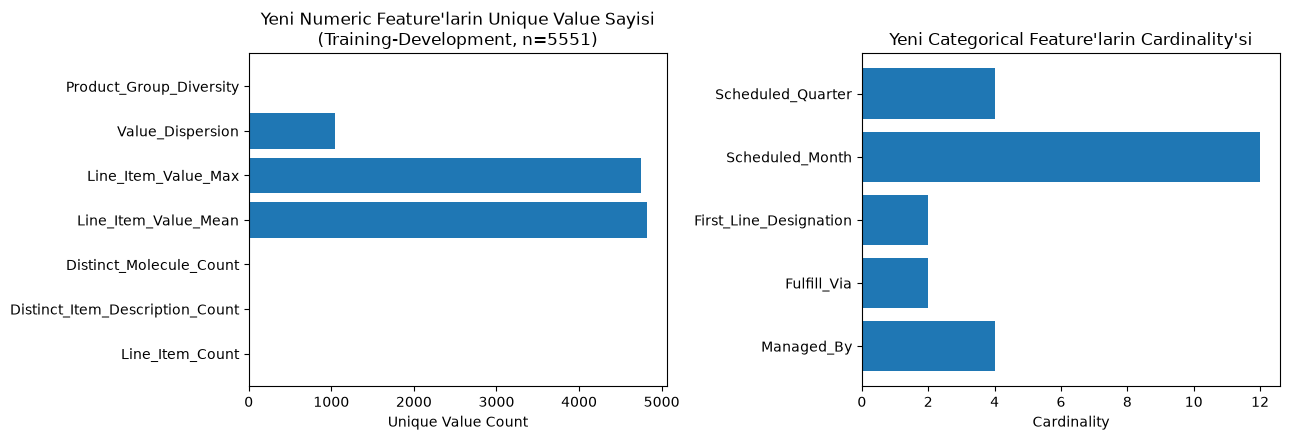

Analysis Question: Hangi yeni feature'lar near-zero-variance riski tasiyor?
Hypothesis: Product_Group_Diversity sifir varyans gosterecek (Section 05'te zaten dogrulandi).
Statistical Observation: tablo yukarida.
Engineering Interpretation: Near_Zero_Variance=True olan feature'lar filter selection'da elenecektir.
Decision Impact: Product_Group_Diversity bu asamadan sonra deneylere dahil edilmeyecek.
Limitations: Bu sadece training-development population'a dayanir, 2014/2015'i yansitmaz.


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
numeric_qual = feature_quality_report[feature_quality_report["Type"] == "Numeric"]
axes[0].barh(numeric_qual["Feature"], numeric_qual["Unique_Values"])
axes[0].set_title("Yeni Numeric Feature'larin Unique Value Sayisi\n(Training-Development, n=%d)" % len(dev_population))
axes[0].set_xlabel("Unique Value Count")

cat_qual = feature_quality_report[feature_quality_report["Type"] == "Categorical"]
axes[1].barh(cat_qual["Feature"], cat_qual["Unique_Values"])
axes[1].set_title("Yeni Categorical Feature'larin Cardinality'si")
axes[1].set_xlabel("Cardinality")
plt.tight_layout()
plt.show()
print("Analysis Question: Hangi yeni feature'lar near-zero-variance riski tasiyor?")
print("Hypothesis: Product_Group_Diversity sifir varyans gosterecek (Section 05'te zaten dogrulandi).")
print("Statistical Observation: tablo yukarida.")
print("Engineering Interpretation: Near_Zero_Variance=True olan feature'lar filter selection'da elenecektir.")
print("Decision Impact: Product_Group_Diversity bu asamadan sonra deneylere dahil edilmeyecek.")
print("Limitations: Bu sadece training-development population'a dayanir, 2014/2015'i yansitmaz.")

## Section 08 — Statistical Feature Diagnostics: Target Relationships

**Learning Objective:** Yeni feature'larin target ile iliskisini, exploratory (hipotez
uretici) bir seviyede incelemek.

**Critical Rule:** Bu bolumdeki korelasyonlar **final feature selection
kararinin yerine gecmez**. "Yuksek korelasyon -> otomatik sec" veya "dusuk korelasyon ->
otomatik ele" cikarimlari yapilmayacaktir. Feature selection icin kullanilan
target-dependent istatistikler, Section 10-12'de **her CV fold'un training data'sinda
yeniden hesaplanacaktir** -- burasi sadece hypothesis-generating bir on-inceleme.

Target-dependent istatistikler, yalnizca **development training observations**
(`Split == "Train"` AND `Has_Numeric_Target`) uzerinde hesaplanir.

In [17]:
dev_eligible = dev_population[dev_population["Has_Numeric_Target"]].copy()
print("Development training, target-eligible observation sayisi:", len(dev_eligible))

numeric_assoc_rows = []
for feat in NEW_NUMERIC_CANDIDATES:
    x = dev_eligible[feat].astype(float)
    y = dev_eligible["Freight_Cost_USD"].astype(float)
    valid = x.notna() & y.notna()
    if valid.sum() < 10 or x[valid].nunique() <= 1:
        numeric_assoc_rows.append({"Feature": feat, "N": int(valid.sum()), "Pearson_r": np.nan, "Spearman_rho": np.nan, "Mutual_Info": np.nan})
        continue
    pearson_r = x[valid].corr(y[valid], method="pearson")
    spearman_rho = x[valid].corr(y[valid], method="spearman")
    mi = mutual_info_regression(x[valid].values.reshape(-1, 1), y[valid].values, random_state=RANDOM_SEED)[0]
    numeric_assoc_rows.append({"Feature": feat, "N": int(valid.sum()), "Pearson_r": round(pearson_r, 4), "Spearman_rho": round(spearman_rho, 4), "Mutual_Info": round(mi, 4)})

numeric_associations = pd.DataFrame(numeric_assoc_rows)
numeric_associations.to_csv(ARTIFACT_DIR / "stage07_numeric_associations.csv", index=False)
print("Wrote stage07_numeric_associations.csv")
numeric_associations

Development training, target-eligible observation sayisi: 4987


Wrote stage07_numeric_associations.csv


,Feature,N,Pearson_r,Spearman_rho,Mutual_Info
0,Line_Item_Count,4987,0.1390,0.1147,0.0225
1,Distinct_Item_Description_Count,4987,0.1117,0.0861,0.0176
2,Distinct_Molecule_Count,4987,0.1108,0.0955,0.0153
3,Line_Item_Value_Mean,4987,0.3694,0.6813,0.4192
4,Line_Item_Value_Max,4987,0.4005,0.6933,0.4376
5,Value_Dispersion,4977,0.1197,0.1124,0.0166
6,Product_Group_Diversity,4987,NaN,NaN,NaN


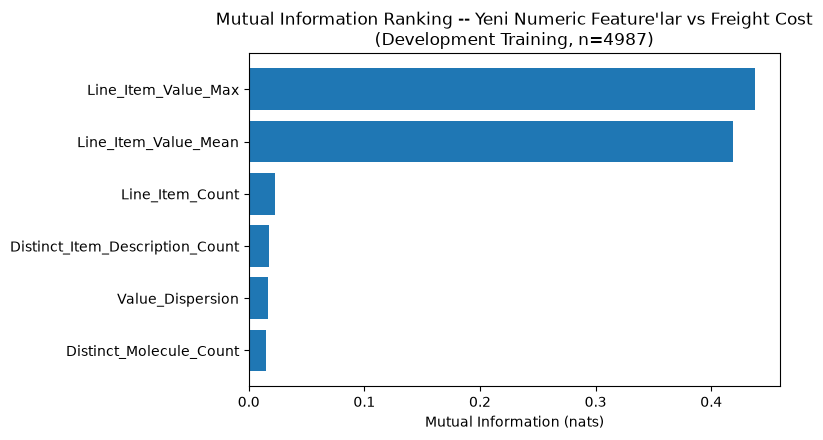

Analysis Question: Hangi yeni numeric feature target ile en yuksek nonlinear iliskiyi gosteriyor?
Hypothesis: Line_Item_Value_Max/Mean, zaten core sette olan Line_Item_Value_Sum ile benzer sinyali tasiyabilir.
Statistical Observation: tablo ve grafik yukarida.
Engineering Interpretation: MI, sadece hipotez uretici bir on-gostergedir; nihai karar CV deneyleriyle verilecektir.
Decision Impact: Bu asamada HENUZ bir feature secimi/elemesi yapilmiyor.
Limitations: MI finite-sample tahmin varyansina sahiptir; tek bir dev-population olcumudur, fold-to-fold degisebilir.


In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df = numeric_associations.dropna(subset=["Mutual_Info"]).sort_values("Mutual_Info")
ax.barh(plot_df["Feature"], plot_df["Mutual_Info"])
ax.set_title("Mutual Information Ranking -- Yeni Numeric Feature'lar vs Freight Cost\n(Development Training, n=%d)" % len(dev_eligible))
ax.set_xlabel("Mutual Information (nats)")
plt.tight_layout()
plt.show()
print("Analysis Question: Hangi yeni numeric feature target ile en yuksek nonlinear iliskiyi gosteriyor?")
print("Hypothesis: Line_Item_Value_Max/Mean, zaten core sette olan Line_Item_Value_Sum ile benzer sinyali tasiyabilir.")
print("Statistical Observation: tablo ve grafik yukarida.")
print("Engineering Interpretation: MI, sadece hipotez uretici bir on-gostergedir; nihai karar CV deneyleriyle verilecektir.")
print("Decision Impact: Bu asamada HENUZ bir feature secimi/elemesi yapilmiyor.")
print("Limitations: MI finite-sample tahmin varyansina sahiptir; tek bir dev-population olcumudur, fold-to-fold degisebilir.")

### Feature Availability vs Feature Quality — Iki Ayri Kayit

**yuksek predictive signal tasiyan bir feature,
prediction-time availability kosulunu saglamiyorsa modelde kullanilamaz.** Bu nedenle iki
ayri karar kaydi tutuyoruz: (1) Statistical/Predictive Evidence, (2) Production
Eligibility. Bu iki kavram birlestirilmez.

In [19]:
eligibility_vs_quality = feature_catalog[["Feature_ID", "Feature_Name", "Feature_Group", "Prediction_Time_Availability", "Decision_Status"]].merge(
    numeric_associations[["Feature", "Mutual_Info"]].rename(columns={"Feature": "Feature_Name"}), on="Feature_Name", how="left"
)
eligibility_vs_quality

,Feature_ID,Feature_Name,Feature_Group,Prediction_Time_Availability,Decision_Status,Mutual_Info
0,F-A1,Line_Item_Count,A - Composition,Available,Accepted for Experimentation,0.0225
1,F-A2,Distinct_Item_Description_Count,A - Composition,Available,Accepted for Experimentation,0.0176
2,F-A3,Distinct_Molecule_Count,A - Composition,Available,Accepted for Experimentation,0.0153
3,F-B1,Line_Item_Value_Mean,B - Value,Conditional (D-010; value/freight bundling risk),Conditional,0.4192
4,F-B2,Line_Item_Value_Max,B - Value,Conditional (D-010; value/freight bundling risk),Conditional,0.4376
5,F-B3,Value_Dispersion,B - Value,Conditional (D-010; value/freight bundling risk),Conditional,0.0166
6,F-C1,Product_Group_Diversity,C - Diversity,N/A -- Rejected (zero variance),"Rejected (constant=1, bkz Section 06)",NaN
7,F-D1,Managed_By,D - Transport/Contract,Available (PO asamasinda bilinir),Accepted for Experimentation,NaN
8,F-D2,Fulfill_Via,D - Transport/Contract,Available (PO asamasinda bilinir),Accepted for Experimentation,NaN
9,F-D3,First_Line_Designation,D - Transport/Contract,Available (planlama asamasinda bilinir),Accepted for Experimentation,NaN


## Section 09 — Feature Redundancy & Multicollinearity

**Learning Objective:** Numeric feature'lar arasindaki pairwise korelasyonu ve olasi
redundancy'yi incelemek.

### Matematiksel Arka Plan

Pearson korelasyonu lineer iliskiyi olcer; Spearman, monoton (lineer olmayabilen) iliskiyi
olcer. Stage 04'te Weight-Freight iliskisinde (Spearman rho ~ 0.73 vs Pearson r ~ 0.14)
gorulen fark, bu ayrimin pratik onemini zaten gostermisti.

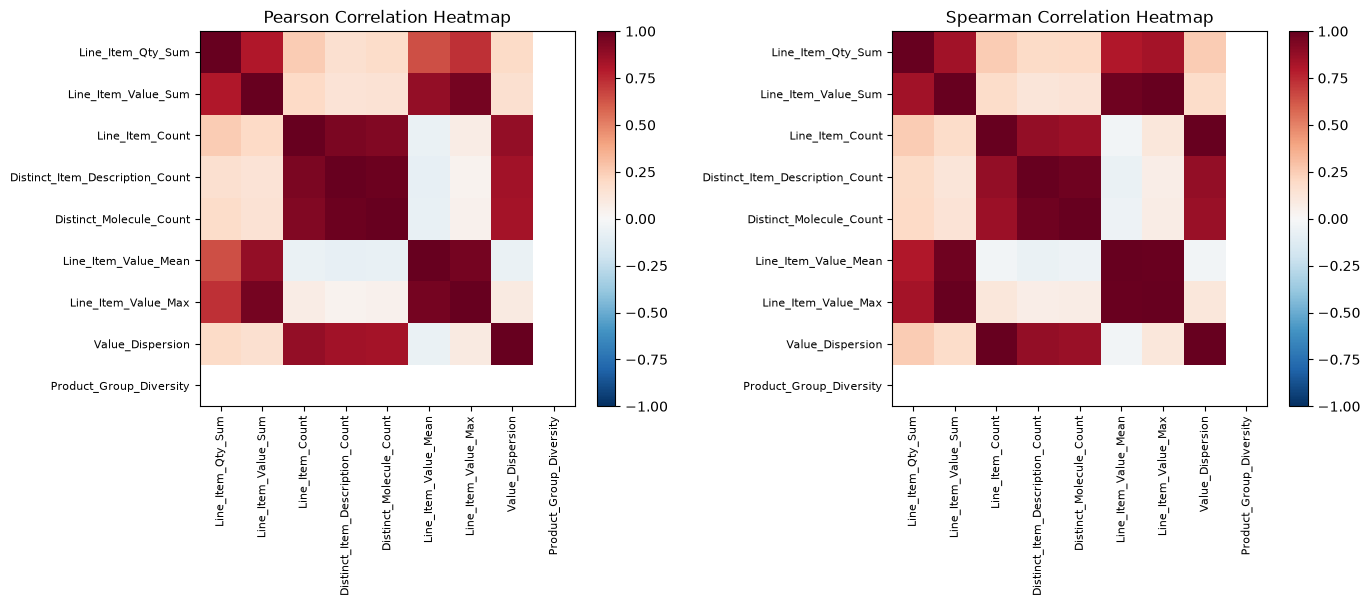

In [20]:
redundancy_features = ["Line_Item_Qty_Sum", "Line_Item_Value_Sum"] + NEW_NUMERIC_CANDIDATES
redundancy_matrix_pearson = dev_eligible[redundancy_features].corr(method="pearson")
redundancy_matrix_spearman = dev_eligible[redundancy_features].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
im0 = axes[0].imshow(redundancy_matrix_pearson.values, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(redundancy_features))); axes[0].set_xticklabels(redundancy_features, rotation=90, fontsize=8)
axes[0].set_yticks(range(len(redundancy_features))); axes[0].set_yticklabels(redundancy_features, fontsize=8)
axes[0].set_title("Pearson Correlation Heatmap")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(redundancy_matrix_spearman.values, cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(redundancy_features))); axes[1].set_xticklabels(redundancy_features, rotation=90, fontsize=8)
axes[1].set_yticks(range(len(redundancy_features))); axes[1].set_yticklabels(redundancy_features, fontsize=8)
axes[1].set_title("Spearman Correlation Heatmap")
plt.colorbar(im1, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

In [21]:
pairs = []
for i, f1 in enumerate(redundancy_features):
    for f2 in redundancy_features[i + 1:]:
        pearson_val = redundancy_matrix_pearson.loc[f1, f2]
        if pd.notna(pearson_val) and abs(pearson_val) >= 0.7:
            pairs.append({"Feature_1": f1, "Feature_2": f2, "Pearson_r": round(pearson_val, 3), "Spearman_rho": round(redundancy_matrix_spearman.loc[f1, f2], 3)})
high_corr_pairs = pd.DataFrame(pairs)
print("High-correlation pairs (|Pearson r| >= 0.7):")
print(high_corr_pairs if len(high_corr_pairs) else "Hic cift bulunamadi -- feature'lar arasinda kayda deger redundancy yok.")
print()
print("Analysis Question: Line_Item_Value_Mean/Max, mevcut Line_Item_Value_Sum ile redundant mi?")
print("Hypothesis: Line_Item_Count dusukse (cogu shipment icin medyan=1), Mean~Max~Sum olabilir.")
print("Engineering Interpretation: Yuksek-korelasyonlu ciftlerden biri, embedded/filter selection'da elenebilir.")
print("Decision Impact: Bu bulgular Section 10-12 feature selection deneylerine girdi olarak kullanilacaktir.")
print("Limitations: Pairwise korelasyon, 3+ feature arasindaki multicollinearity'yi tam yakalamaz (VIF daha uygun olurdu).")

High-correlation pairs (|Pearson r| >= 0.7):
                          Feature_1                        Feature_2  \
0                 Line_Item_Qty_Sum              Line_Item_Value_Sum   
1                 Line_Item_Qty_Sum              Line_Item_Value_Max   
2               Line_Item_Value_Sum             Line_Item_Value_Mean   
3               Line_Item_Value_Sum              Line_Item_Value_Max   
4                   Line_Item_Count  Distinct_Item_Description_Count   
5                   Line_Item_Count          Distinct_Molecule_Count   
6                   Line_Item_Count                 Value_Dispersion   
7   Distinct_Item_Description_Count          Distinct_Molecule_Count   
8   Distinct_Item_Description_Count                 Value_Dispersion   
9           Distinct_Molecule_Count                 Value_Dispersion   
10             Line_Item_Value_Mean              Line_Item_Value_Max   

    Pearson_r  Spearman_rho  
0       0.804         0.843  
1       0.732         0.829  


In [22]:
aggregation_diagnostics_rows = []
for feat in ["Line_Item_Count", "Distinct_Item_Description_Count", "Distinct_Molecule_Count"]:
    aggregation_diagnostics_rows.append({
        "Feature": feat, "Mean": round(dev_population[feat].mean(), 2), "Median": dev_population[feat].median(),
        "Max": dev_population[feat].max(), "Pct_Shipments_With_Single_Line": round(100 * (dev_population["Line_Item_Count"] == 1).mean(), 2),
    })
aggregation_diagnostics = pd.DataFrame(aggregation_diagnostics_rows)
aggregation_diagnostics.to_csv(ARTIFACT_DIR / "stage07_aggregation_diagnostics.csv", index=False)
print("Wrote stage07_aggregation_diagnostics.csv")
aggregation_diagnostics

Wrote stage07_aggregation_diagnostics.csv


,Feature,Mean,Median,Max,Pct_Shipments_With_Single_Line
0,Line_Item_Count,1.40,1.0,54,80.35
1,Distinct_Item_Description_Count,1.32,1.0,23,80.35
2,Distinct_Molecule_Count,1.28,1.0,11,80.35


## Section 10 — Feature Selection Methods: CV Infrastructure

**Learning Objective:** Feature Selection'in Pipeline icerisinde, fold-training-only fit
edildigi, leakage-safe bir mimari insa etmek.

### Dogru Mimari

```
Fold Training -> Feature Engineering -> ColumnTransformer -> Feature Selector -> Probe Estimator -> Fold Validation Prediction
```

Feature Selection, bu Pipeline'in **icerisinde** ve **sadece fold training data'sinda**
fit edilir -- hicbir zaman butun development population uzerinde onceden fit edilip CV'ye
sokulmaz.

**Frozen Configuration Rule:** Preprocessing yontemleri (imputation, encoding, scaling)
butun feature-set karsilastirmalarinda **sabit** tutulur -- sadece `ColumnTransformer`'in
kolon listeleri feature schema'ya gore degisir.

In [23]:
def build_preprocessor(numeric_features, categorical_features):
    # Frozen preprocessing policy (Stage 06 "Preferred" tier): median imputation +
    # StandardScaler for numeric, constant-fill + rare-category-grouped OneHot for categorical.
    # Only the column lists change across feature-set comparisons (Frozen Configuration Rule).
    from sklearn.preprocessing import StandardScaler
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False)),
    ])
    transformers = []
    if numeric_features:
        transformers.append(("numeric", numeric_pipeline, numeric_features))
    if categorical_features:
        transformers.append(("categorical", categorical_pipeline, categorical_features))
    return ColumnTransformer(transformers)


def build_feature_pipeline(numeric_features, categorical_features, estimator_name, selector=None):
    preprocessor = build_preprocessor(numeric_features, categorical_features)
    steps = [("preprocessor", preprocessor)]
    if selector is not None:
        steps.append(("selector", selector))
    steps.append(("model", get_probe_estimator(estimator_name)))
    return Pipeline(steps)


def run_feature_cv_experiment(experiment_id, candidate_id, numeric_features, categorical_features, estimator_name, selector=None):
    # Runs one feature-set configuration across all 4 frozen Stage 05 CV folds.
    # Fold membership and evaluation population come entirely from the frozen manifest --
    # never modified here.
    fold_rows, oof_rows = [], []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for fold_id in sorted(cv_fold_manifest_s05["Fold_ID"].unique()):
            manifest = cv_fold_manifest_s05[cv_fold_manifest_s05["Fold_ID"] == fold_id]
            train_keys = set(manifest.loc[manifest["Role"] == "Train", "Shipment_Key"])
            val_keys = set(manifest.loc[manifest["Role"] == "CV_Validation", "Shipment_Key"])
            train_df = shipment_view[shipment_view[PRIMARY_KEY].isin(train_keys) & shipment_view["Has_Numeric_Target"]]
            val_df = shipment_view[shipment_view[PRIMARY_KEY].isin(val_keys) & shipment_view["Has_Numeric_Target"]]

            all_feats = numeric_features + categorical_features
            X_train, y_train = train_df[all_feats], train_df["Freight_Cost_USD"].astype(float)
            X_val, y_val = val_df[all_feats], val_df["Freight_Cost_USD"].astype(float)

            pipeline = build_feature_pipeline(numeric_features, categorical_features, estimator_name, selector=clone(selector) if selector is not None else None)
            t0 = time.perf_counter()
            pipeline.fit(X_train, y_train)
            fit_time = time.perf_counter() - t0
            t0 = time.perf_counter()
            raw_preds = pipeline.predict(X_val)
            predict_time = time.perf_counter() - t0
            preds = np.clip(raw_preds, 0.0, None)

            mae = float(np.mean(np.abs(y_val.values - preds)))
            rmse = float(np.sqrt(np.mean((y_val.values - preds) ** 2)))
            bias = float(np.mean(preds - y_val.values))
            wape = float(np.sum(np.abs(y_val.values - preds)) / np.sum(np.abs(y_val.values)))
            median_ae = float(np.median(np.abs(y_val.values - preds)))
            high_cost_threshold = y_train.quantile(0.90)
            hc_mask = y_val.values >= high_cost_threshold
            high_cost_mae = float(np.mean(np.abs(y_val.values[hc_mask] - preds[hc_mask]))) if hc_mask.sum() > 0 else np.nan

            n_selected = None
            if "selector" in pipeline.named_steps:
                n_selected = int(pipeline.named_steps["selector"].get_support().sum())

            fold_rows.append({
                "Experiment_ID": experiment_id, "Candidate_ID": candidate_id, "Estimator": estimator_name,
                "Fold_ID": int(fold_id), "Train_Count": len(train_df), "Validation_Count": len(val_df),
                "Feature_Count": len(all_feats), "N_Selected_Encoded_Features": n_selected,
                "MAE": mae, "RMSE": rmse, "Median_AE": median_ae, "WAPE": wape, "Bias": bias, "High_Cost_MAE": high_cost_mae,
                "Fit_Time_s": fit_time, "Predict_Time_s": predict_time,
            })
            for key, actual, pred in zip(val_df[PRIMARY_KEY].values, y_val.values, preds):
                oof_rows.append({"Experiment_ID": experiment_id, "Candidate_ID": candidate_id, "Estimator": estimator_name,
                                  "Fold_ID": int(fold_id), "Shipment_Key": key, "Actual": actual, "Prediction": pred})
    return pd.DataFrame(fold_rows), pd.DataFrame(oof_rows)


def pooled_mae(fold_df):
    return float((fold_df["MAE"] * fold_df["Validation_Count"]).sum() / fold_df["Validation_Count"].sum())


# Smoke test: one fold's worth of logic validated via a single tiny config before any heavy run.
_smoke_fold_df, _smoke_oof_df = run_feature_cv_experiment(
    "SMOKE", "core_ridge", stage06_contract["numeric_features"], stage06_contract["categorical_features"], "Ridge"
)
print("Smoke test (core features, Ridge) fold results:")
print(_smoke_fold_df[["Fold_ID", "Train_Count", "Validation_Count", "MAE"]])
assert _smoke_oof_df["Shipment_Key"].is_unique
print("\nSmoke test passed -- CV infrastructure verified before heavy experimentation.")

Smoke test (core features, Ridge) fold results:
   Fold_ID  Train_Count  Validation_Count          MAE
0        1         1735               780  6840.305691
1        2         2515               776  7029.196601
2        3         3291               861  8899.019377
3        4         4152               835  8960.599379

Smoke test passed -- CV infrastructure verified before heavy experimentation.


### Feature Configuration Registry (F0-F5 + Conditional Sets)

Bu konfigurasyonlar, hem Feature Selection (Section 10-12) hem de Ablation (Section 14)
bolumlerinde ayni sekilde kullanilacaktir.

In [24]:
CORE_NUMERIC = list(stage06_contract["numeric_features"])
CORE_CATEGORICAL = list(stage06_contract["categorical_features"])

FEATURE_CONFIGS = {
    "F0_core": {"numeric": CORE_NUMERIC, "categorical": CORE_CATEGORICAL},
    "F1_composition": {"numeric": CORE_NUMERIC + ["Line_Item_Count", "Distinct_Item_Description_Count", "Distinct_Molecule_Count"], "categorical": CORE_CATEGORICAL},
    "F2_value": {"numeric": CORE_NUMERIC + ["Line_Item_Value_Mean", "Line_Item_Value_Max", "Value_Dispersion"], "categorical": CORE_CATEGORICAL},
    "F3_diversity": {"numeric": CORE_NUMERIC + ["Product_Group_Diversity"], "categorical": CORE_CATEGORICAL},
    "F4_combined": {
        "numeric": CORE_NUMERIC + ["Line_Item_Count", "Distinct_Item_Description_Count", "Distinct_Molecule_Count", "Line_Item_Value_Mean", "Line_Item_Value_Max", "Value_Dispersion"],
        "categorical": CORE_CATEGORICAL + ["Managed_By", "Fulfill_Via", "First_Line_Designation"],
    },
}
# Conditional / sensitivity-only configurations -- kept separate from the production-oriented comparison.
CONDITIONAL_CONFIGS = {
    "Weight_Sensitivity": {"numeric": FEATURE_CONFIGS["F4_combined"]["numeric"] + ["Weight_KG"], "categorical": FEATURE_CONFIGS["F4_combined"]["categorical"]},
    "Calendar_Sensitivity": {"numeric": FEATURE_CONFIGS["F4_combined"]["numeric"], "categorical": FEATURE_CONFIGS["F4_combined"]["categorical"] + ["Scheduled_Month", "Scheduled_Quarter"]},
}
for name, cfg in FEATURE_CONFIGS.items():
    print(f"{name}: {len(cfg['numeric']) + len(cfg['categorical'])} raw features ({len(cfg['numeric'])} numeric, {len(cfg['categorical'])} categorical)")
for name, cfg in CONDITIONAL_CONFIGS.items():
    print(f"{name} (conditional): {len(cfg['numeric']) + len(cfg['categorical'])} raw features")

F0_core: 6 raw features (2 numeric, 4 categorical)
F1_composition: 9 raw features (5 numeric, 4 categorical)
F2_value: 9 raw features (5 numeric, 4 categorical)
F3_diversity: 7 raw features (3 numeric, 4 categorical)
F4_combined: 15 raw features (8 numeric, 7 categorical)
Weight_Sensitivity (conditional): 16 raw features
Calendar_Sensitivity (conditional): 17 raw features


## Section 11 — Filter Feature Selection

**Learning Objective:** `SelectKBest` (mutual_info_regression) ile filter-based selection
uygulamak; `k` degerini onceden tanimlanmis, sinirli candidate'lar icinde tutmak.

### Matematiksel Arka Plan

Variance: Var(X) = E[(X-mu)^2]. Pearson correlation, lineer iliskiyi yakalar; Mutual
Information nonlinear bagimliliklari da yakalayabilir, ancak finite-sample estimation
varyansi tasir (kucuk fold-training orneklerinde gurultulu olabilir).

Filter selector, **her fold'un training data'sinda yeniden fit edilir** -- k degeri
onceden sabitlenmis {5, 10, 15} adaylarindan secilir (CV validation performansina bakip
sinirsiz ayarlanmaz).

In [25]:
FILTER_K_CANDIDATES = stage07_cfg["feature_selection"]["filter"]["k_candidates"]
filter_fold_results, filter_oof_results = [], []
for k in FILTER_K_CANDIDATES:
    for estimator_name in ["Ridge", "Random_Forest"]:
        selector = SelectKBest(score_func=lambda X, y: mutual_info_regression(X, y, random_state=RANDOM_SEED), k=k)
        fold_df, oof_df = run_feature_cv_experiment(f"FILTER_k{k}", f"filter_k{k}", FEATURE_CONFIGS["F4_combined"]["numeric"], FEATURE_CONFIGS["F4_combined"]["categorical"], estimator_name, selector=selector)
        filter_fold_results.append(fold_df)
        filter_oof_results.append(oof_df)
filter_fold_results = pd.concat(filter_fold_results, ignore_index=True)
filter_oof_results = pd.concat(filter_oof_results, ignore_index=True)
print("Filter selection fold results shape:", filter_fold_results.shape)
filter_fold_results.groupby(["Candidate_ID", "Estimator"]).apply(lambda g: pooled_mae(g), include_groups=False).rename("Pooled_MAE").reset_index()

Filter selection fold results shape: (24, 16)


,Candidate_ID,Estimator,Pooled_MAE
0,filter_k10,Random_Forest,6683.633743
1,filter_k10,Ridge,8150.684939
2,filter_k15,Random_Forest,6421.881547
3,filter_k15,Ridge,8155.765061
4,filter_k5,Random_Forest,6883.237763
5,filter_k5,Ridge,8214.423424


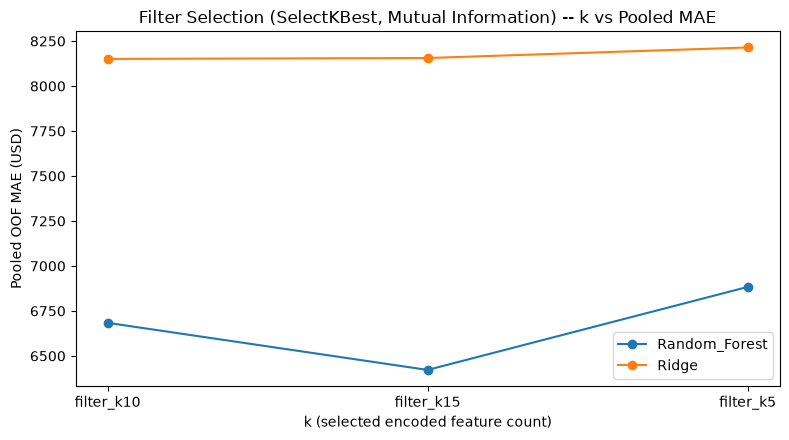

Analysis Question: k arttikca pooled MAE nasil degisiyor?
Hypothesis: F4'teki bazi feature'lar redundant (Section 09), kucuk k ile de benzer performans alinabilir.
Statistical Observation: grafik ve tablo yukarida.
Engineering Interpretation: k secimi, feature-count/complexity ile MAE arasindaki trade-off'u yansitir.
Decision Impact: En iyi k, Section 17'de Preferred/Acceptable/Inconclusive olarak siniflandirilacaktir.
Limitations: Mutual information, kucuk fold-training orneklerinde (Fold 1: n=1735) gurultulu olabilir.


In [26]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_data = filter_fold_results.groupby(["Candidate_ID", "Estimator"]).apply(lambda g: pooled_mae(g), include_groups=False).rename("Pooled_MAE").reset_index()
for estimator_name, sub in plot_data.groupby("Estimator"):
    ax.plot(sub["Candidate_ID"], sub["Pooled_MAE"], marker="o", label=estimator_name)
ax.set_title("Filter Selection (SelectKBest, Mutual Information) -- k vs Pooled MAE")
ax.set_xlabel("k (selected encoded feature count)")
ax.set_ylabel("Pooled OOF MAE (USD)")
ax.legend()
plt.tight_layout()
plt.show()
print("Analysis Question: k arttikca pooled MAE nasil degisiyor?")
print("Hypothesis: F4'teki bazi feature'lar redundant (Section 09), kucuk k ile de benzer performans alinabilir.")
print("Statistical Observation: grafik ve tablo yukarida.")
print("Engineering Interpretation: k secimi, feature-count/complexity ile MAE arasindaki trade-off'u yansitir.")
print("Decision Impact: En iyi k, Section 17'de Preferred/Acceptable/Inconclusive olarak siniflandirilacaktir.")
print("Limitations: Mutual information, kucuk fold-training orneklerinde (Fold 1: n=1735) gurultulu olabilir.")

## Section 12 — Embedded Feature Selection

**Learning Objective:** `SelectFromModel` + `Lasso` (L1-regularized) ile embedded
selection uygulamak.

**Onemli:** Ridge coefficients dogal olarak sparse degildir (L2 regularization hicbir
katsayiyi tam sifira indirmez). Bu nedenle feature selection icin **ayri bir Lasso
selector estimator** kullaniyoruz -- Lasso'nun kendisi final model DEGILDIR, sadece
hangi (encoded) feature'larin sifir-disi katsayi aldigini belirlemek icin kullanilir.
Lasso'nun `alpha` parametresi Stage 07 kapsamini genisletecek sekilde optimize
edilmemistir -- tek, sabit bir deger kullanilmistir.

In [27]:
LASSO_ALPHA = 50.0  # fixed, not tuned -- chosen only to produce a non-trivial sparse subset.
embedded_selector = SelectFromModel(Lasso(alpha=LASSO_ALPHA, random_state=RANDOM_SEED, max_iter=5000))

embedded_fold_results, embedded_oof_results = [], []
for estimator_name in ["Ridge", "Random_Forest"]:
    fold_df, oof_df = run_feature_cv_experiment("EMBEDDED", "lasso_selectfrommodel", FEATURE_CONFIGS["F4_combined"]["numeric"], FEATURE_CONFIGS["F4_combined"]["categorical"], estimator_name, selector=embedded_selector)
    embedded_fold_results.append(fold_df)
    embedded_oof_results.append(oof_df)
embedded_fold_results = pd.concat(embedded_fold_results, ignore_index=True)
embedded_oof_results = pd.concat(embedded_oof_results, ignore_index=True)
print("Embedded selection -- selected encoded feature count per fold:")
print(embedded_fold_results[["Estimator", "Fold_ID", "N_Selected_Encoded_Features"]])
print()
print("Pooled MAE:")
print(embedded_fold_results.groupby("Estimator").apply(lambda g: pooled_mae(g), include_groups=False).rename("Pooled_MAE"))

Embedded selection -- selected encoded feature count per fold:
       Estimator  Fold_ID  N_Selected_Encoded_Features
0          Ridge        1                           23
1          Ridge        2                           23
2          Ridge        3                           21
3          Ridge        4                           24
4  Random_Forest        1                           23
5  Random_Forest        2                           23
6  Random_Forest        3                           21
7  Random_Forest        4                           24

Pooled MAE:
Estimator
Random_Forest    6332.239095
Ridge            8065.871598
Name: Pooled_MAE, dtype: float64


**Onemli Tree-Based Not:** Tree-based importance (impurity-based) high-cardinality ve
correlated feature'lar karsisinda bias tasiyabilir -- bu nedenle embedded selection icin
Random Forest importance degil, Lasso tercih edilmistir (daha yorumlanabilir sparsity).
Random Forest, sadece Lasso'nun SECTIGI feature subset'i ile DEGERLENDIRILMEKTEDIR
(kendi importance'ina gore degil).

## Section 13 — Wrapper Feature Selection (Limited)

**Learning Objective:** `RFE` ile sinirli bir wrapper selection denemesi yapmak.

**Runtime Restriction:** Wrapper yontemleri yogun hesaplama gerektirebilir. Bu nedenle:
sabit `n_features_to_select=8`, `step=2`, sabit base estimator (Ridge -- `coef_`
gerektirir), sabit CV protokolu kullanilmistir. **Exhaustive subset search yapilmamistir.**

In [28]:
WRAPPER_N_FEATURES = stage07_cfg["feature_selection"]["wrapper"]["n_features_to_select"]
WRAPPER_STEP = stage07_cfg["feature_selection"]["wrapper"]["step"]
wrapper_selector = RFE(estimator=Ridge(alpha=PROBE_PARAMS["ridge"]["alpha"]), n_features_to_select=WRAPPER_N_FEATURES, step=WRAPPER_STEP)

wrapper_fold_results, wrapper_oof_results = [], []
for estimator_name in ["Ridge", "Random_Forest"]:
    fold_df, oof_df = run_feature_cv_experiment("WRAPPER", "rfe_ridge_base", FEATURE_CONFIGS["F4_combined"]["numeric"], FEATURE_CONFIGS["F4_combined"]["categorical"], estimator_name, selector=clone(wrapper_selector))
    wrapper_fold_results.append(fold_df)
    wrapper_oof_results.append(oof_df)
wrapper_fold_results = pd.concat(wrapper_fold_results, ignore_index=True)
wrapper_oof_results = pd.concat(wrapper_oof_results, ignore_index=True)
print("Wrapper selection (RFE, Ridge base, n_features_to_select=%d) -- Pooled MAE:" % WRAPPER_N_FEATURES)
print(wrapper_fold_results.groupby("Estimator").apply(lambda g: pooled_mae(g), include_groups=False).rename("Pooled_MAE"))

Wrapper selection (RFE, Ridge base, n_features_to_select=8) -- Pooled MAE:
Estimator
Random_Forest    7438.382066
Ridge            8645.195671
Name: Pooled_MAE, dtype: float64


In [29]:
feature_selection_results = pd.concat([
    filter_fold_results.assign(Method="Filter"),
    embedded_fold_results.assign(Method="Embedded"),
    wrapper_fold_results.assign(Method="Wrapper"),
], ignore_index=True)

no_selection_fold_df, no_selection_oof_df = run_feature_cv_experiment("NO_SELECTION", "f4_full", FEATURE_CONFIGS["F4_combined"]["numeric"], FEATURE_CONFIGS["F4_combined"]["categorical"], "Ridge")
no_selection_fold_df_rf, _ = run_feature_cv_experiment("NO_SELECTION", "f4_full", FEATURE_CONFIGS["F4_combined"]["numeric"], FEATURE_CONFIGS["F4_combined"]["categorical"], "Random_Forest")
feature_selection_results = pd.concat([feature_selection_results, no_selection_fold_df.assign(Method="No_Selection"), no_selection_fold_df_rf.assign(Method="No_Selection")], ignore_index=True)

feature_selection_results.to_csv(ARTIFACT_DIR / "stage07_feature_selection_results.csv", index=False)
print("Wrote stage07_feature_selection_results.csv --", len(feature_selection_results), "rows")

selection_summary = feature_selection_results.groupby(["Method", "Candidate_ID", "Estimator"]).apply(
    lambda g: pd.Series({"Pooled_MAE": pooled_mae(g), "Mean_Selected_Features": g["N_Selected_Encoded_Features"].mean(), "Mean_Fit_Time_s": g["Fit_Time_s"].mean()}),
    include_groups=False,
).reset_index()
selection_summary

Wrote stage07_feature_selection_results.csv -- 48 rows


,Method,Candidate_ID,Estimator,Pooled_MAE,Mean_Selected_Features,Mean_Fit_Time_s
0,Embedded,lasso_selectfrommodel,Random_Forest,6332.239095,22.75,0.196071
1,Embedded,lasso_selectfrommodel,Ridge,8065.871598,22.75,0.022005
2,Filter,filter_k10,Random_Forest,6683.633743,10.00,0.586364
3,Filter,filter_k10,Ridge,8150.684939,10.00,0.387125
4,Filter,filter_k15,Random_Forest,6421.881547,15.00,0.580896
5,Filter,filter_k15,Ridge,8155.765061,15.00,0.388472
6,Filter,filter_k5,Random_Forest,6883.237763,5.00,0.556174
7,Filter,filter_k5,Ridge,8214.423424,5.00,0.388467
8,No_Selection,f4_full,Random_Forest,6239.416453,NaN,0.257395
9,No_Selection,f4_full,Ridge,7921.116779,NaN,0.016924


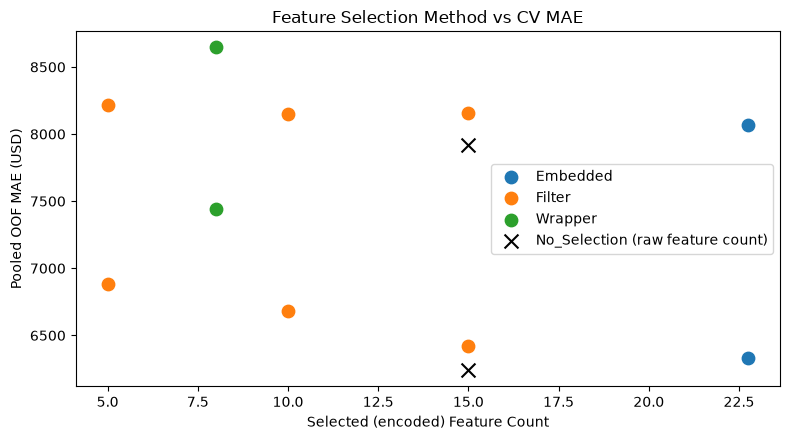

Analysis Question: Daha az feature ile benzer veya daha iyi performans elde edilebiliyor mu?
Hypothesis: Section 09'daki redundancy bulgusu nedeniyle, filter/embedded ile azaltilmis setler No_Selection'a yakin performans verebilir.
Statistical Observation: grafik ve tablo yukarida.
Engineering Interpretation: Feature count ile MAE arasindaki trade-off, Section 17 karar kriterlerine girdi olusturur.
Decision Impact: En iyi yontem(ler) Preferred/Acceptable/Inconclusive/Rejected olarak siniflandirilacaktir (Section 17).
Limitations: Sadece 2 probe estimator ve sinirli k/alpha/n_features degerleri denendi -- exhaustive degil.


In [30]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for method, sub in selection_summary.dropna(subset=["Mean_Selected_Features"]).groupby("Method"):
    ax.scatter(sub["Mean_Selected_Features"], sub["Pooled_MAE"], label=method, s=80)
no_sel = selection_summary[selection_summary["Method"] == "No_Selection"]
ax.scatter([len(FEATURE_CONFIGS["F4_combined"]["numeric"]) + len(FEATURE_CONFIGS["F4_combined"]["categorical"])] * len(no_sel), no_sel["Pooled_MAE"], label="No_Selection (raw feature count)", marker="x", s=100, color="black")
ax.set_xlabel("Selected (encoded) Feature Count")
ax.set_ylabel("Pooled OOF MAE (USD)")
ax.set_title("Feature Selection Method vs CV MAE")
ax.legend()
plt.tight_layout()
plt.show()
print("Analysis Question: Daha az feature ile benzer veya daha iyi performans elde edilebiliyor mu?")
print("Hypothesis: Section 09'daki redundancy bulgusu nedeniyle, filter/embedded ile azaltilmis setler No_Selection'a yakin performans verebilir.")
print("Statistical Observation: grafik ve tablo yukarida.")
print("Engineering Interpretation: Feature count ile MAE arasindaki trade-off, Section 17 karar kriterlerine girdi olusturur.")
print("Decision Impact: En iyi yontem(ler) Preferred/Acceptable/Inconclusive/Rejected olarak siniflandirilacaktir (Section 17).")
print("Limitations: Sadece 2 probe estimator ve sinirli k/alpha/n_features degerleri denendi -- exhaustive degil.")

## Section 14 — Feature Group Ablation & Comparative Benchmarking

**Learning Objective:** Yeni feature group'larin model performansina gercek katkisini
kontrollu deneylerle olcmek.

**Core Question:** Bir feature group'u modele eklediğimizde veya modelden cikardigimizda
prediction error nasil degisiyor?

**Definition -- Ablation Study:** belirli bir feature group'un katkisini anlamak icin o
grubu kontrollu bicimde kaldirarak veya ekleyerek yapilan deney.

**Difference Convention (butun notebook boyunca sabit):**

Delta_MAE = MAE_candidate - MAE_reference

Negatif -> candidate iyilestirir. Pozitif -> candidate kotulestirir.

**Frozen Configuration Rule:** Preprocessing (median+StandardScaler+rare-category OneHot)
butun ablation konfigurasyonlarinda sabit -- sadece ColumnTransformer kolon listeleri
feature schema'ya gore degisir.

In [31]:
ablation_fold_results = []
for config_name, cfg in FEATURE_CONFIGS.items():
    for estimator_name in ["Ridge", "Random_Forest"]:
        fold_df, oof_df = run_feature_cv_experiment("ABLATION_ADD", config_name, cfg["numeric"], cfg["categorical"], estimator_name)
        ablation_fold_results.append(fold_df)
ablation_add_one_group = pd.concat(ablation_fold_results, ignore_index=True)

ablation_pooled = ablation_add_one_group.groupby(["Candidate_ID", "Estimator"]).apply(lambda g: pooled_mae(g), include_groups=False).rename("Pooled_MAE").reset_index()
reference_pooled = ablation_pooled[ablation_pooled["Candidate_ID"] == "F0_core"].set_index("Estimator")["Pooled_MAE"]
ablation_pooled["Delta_MAE_vs_F0"] = ablation_pooled.apply(lambda r: r["Pooled_MAE"] - reference_pooled[r["Estimator"]], axis=1)
ablation_pooled

,Candidate_ID,Estimator,Pooled_MAE,Delta_MAE_vs_F0
0,F0_core,Random_Forest,6151.742895,0.000000
1,F0_core,Ridge,7974.861982,0.000000
2,F1_composition,Random_Forest,6137.966763,-13.776132
3,F1_composition,Ridge,7916.687484,-58.174498
4,F2_value,Random_Forest,6251.472297,99.729402
5,F2_value,Ridge,7944.260194,-30.601789
6,F3_diversity,Random_Forest,6151.175968,-0.566928
7,F3_diversity,Ridge,7974.861982,0.000000
8,F4_combined,Random_Forest,6239.416453,87.673558
9,F4_combined,Ridge,7921.116779,-53.745204


### Hypothesis Confirmation — F3 (Product Diversity) Should Equal F0

Section 05/07'de zaten dogrulandi: `Product_Group_Diversity` sifir varyans. Bu nedenle
**F3'un F0'dan farkli olmamasi beklenir** -- bu, built-in bir sanity check'tir.

In [32]:
f0_f3_diff = ablation_pooled[ablation_pooled["Candidate_ID"].isin(["F0_core", "F3_diversity"])].pivot(index="Estimator", columns="Candidate_ID", values="Pooled_MAE")
f0_f3_diff["Difference"] = f0_f3_diff["F3_diversity"] - f0_f3_diff["F0_core"]
print(f0_f3_diff)
print()
print("BEKLENEN: Difference ~ 0 (Product_Group_Diversity zero-variance oldugu icin ColumnTransformer'a")
print("eklenmesi/cikarilmasi hicbir sinyal eklemez). Kucuk farklar sadece numeric float noise'dur.")

Candidate_ID       F0_core  F3_diversity  Difference
Estimator                                           
Random_Forest  6151.742895   6151.175968   -0.566928
Ridge          7974.861982   7974.861982    0.000000

BEKLENEN: Difference ~ 0 (Product_Group_Diversity zero-variance oldugu icin ColumnTransformer'a
eklenmesi/cikarilmasi hicbir sinyal eklemez). Kucuk farklar sadece numeric float noise'dur.


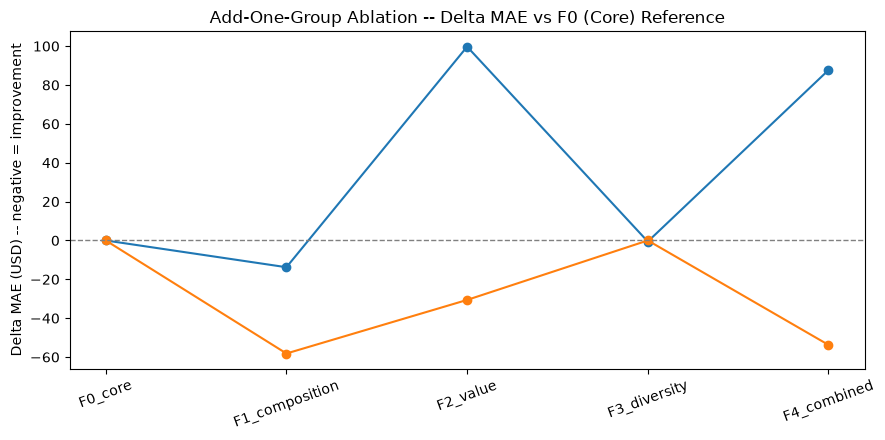

Analysis Question: Hangi feature group'u eklemek pooled MAE'yi en cok iyilestiriyor/kotulestiriyor?
Hypothesis: F1 (Composition) ve F4 (Combined), redundancy'ye ragmen bir miktar katki saglayabilir.
Statistical Observation: grafik yukarida.
Engineering Interpretation: Delta_MAE'nin isareti ve buyuklugu, Section 17 Engineering Decision girdisidir.
Decision Impact: 'Adds Consistent Value' / 'Adds Model-Dependent Value' / 'Redundant' / 'Inconclusive' siniflandirmasi yapilacaktir.
Limitations: Yalnizca 4 fold -- fold-fold MAE dalgalanmasi (Stage 06'da ~%30 gözlendi) sonuclari sinirlar.


In [33]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for estimator_name, sub in ablation_pooled.groupby("Estimator"):
    sub_sorted = sub.set_index("Candidate_ID").loc[["F0_core", "F1_composition", "F2_value", "F3_diversity", "F4_combined"]]
    ax.plot(sub_sorted.index, sub_sorted["Delta_MAE_vs_F0"], marker="o", label=estimator_name)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_title("Add-One-Group Ablation -- Delta MAE vs F0 (Core) Reference")
ax.set_ylabel("Delta MAE (USD) -- negative = improvement")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
print("Analysis Question: Hangi feature group'u eklemek pooled MAE'yi en cok iyilestiriyor/kotulestiriyor?")
print("Hypothesis: F1 (Composition) ve F4 (Combined), redundancy'ye ragmen bir miktar katki saglayabilir.")
print("Statistical Observation: grafik yukarida.")
print("Engineering Interpretation: Delta_MAE'nin isareti ve buyuklugu, Section 17 Engineering Decision girdisidir.")
print("Decision Impact: 'Adds Consistent Value' / 'Adds Model-Dependent Value' / 'Redundant' / 'Inconclusive' siniflandirmasi yapilacaktir.")
print("Limitations: Yalnizca 4 fold -- fold-fold MAE dalgalanmasi (Stage 06'da ~%30 gözlendi) sonuclari sinirlar.")

### Drop-One-Group Ablation

F4 (Combined Eligible) referans alinir; her defasinda **tek bir grup** cikarilir.

In [34]:
DROP_ONE_CONFIGS = {
    "F4_minus_composition": {"numeric": [f for f in FEATURE_CONFIGS["F4_combined"]["numeric"] if f not in ["Line_Item_Count", "Distinct_Item_Description_Count", "Distinct_Molecule_Count"]], "categorical": FEATURE_CONFIGS["F4_combined"]["categorical"]},
    "F4_minus_value": {"numeric": [f for f in FEATURE_CONFIGS["F4_combined"]["numeric"] if f not in ["Line_Item_Value_Mean", "Line_Item_Value_Max", "Value_Dispersion"]], "categorical": FEATURE_CONFIGS["F4_combined"]["categorical"]},
    "F4_minus_transport_ext": {"numeric": FEATURE_CONFIGS["F4_combined"]["numeric"], "categorical": [f for f in FEATURE_CONFIGS["F4_combined"]["categorical"] if f not in ["Managed_By", "Fulfill_Via", "First_Line_Designation"]]},
}
drop_one_results = []
for config_name, cfg in DROP_ONE_CONFIGS.items():
    for estimator_name in ["Ridge", "Random_Forest"]:
        fold_df, oof_df = run_feature_cv_experiment("ABLATION_DROP", config_name, cfg["numeric"], cfg["categorical"], estimator_name)
        drop_one_results.append(fold_df)
ablation_drop_one_group = pd.concat(drop_one_results, ignore_index=True)

drop_pooled = ablation_drop_one_group.groupby(["Candidate_ID", "Estimator"]).apply(lambda g: pooled_mae(g), include_groups=False).rename("Pooled_MAE").reset_index()
f4_pooled = ablation_pooled[ablation_pooled["Candidate_ID"] == "F4_combined"].set_index("Estimator")["Pooled_MAE"]
drop_pooled["Delta_MAE_vs_F4"] = drop_pooled.apply(lambda r: r["Pooled_MAE"] - f4_pooled[r["Estimator"]], axis=1)
drop_pooled

,Candidate_ID,Estimator,Pooled_MAE,Delta_MAE_vs_F4
0,F4_minus_composition,Random_Forest,6255.984356,16.567903
1,F4_minus_composition,Ridge,7950.965351,29.848572
2,F4_minus_transport_ext,Random_Forest,6233.760054,-5.656399
3,F4_minus_transport_ext,Ridge,7915.714662,-5.402117
4,F4_minus_value,Random_Forest,6143.781709,-95.634744
5,F4_minus_value,Ridge,7921.850744,0.733966


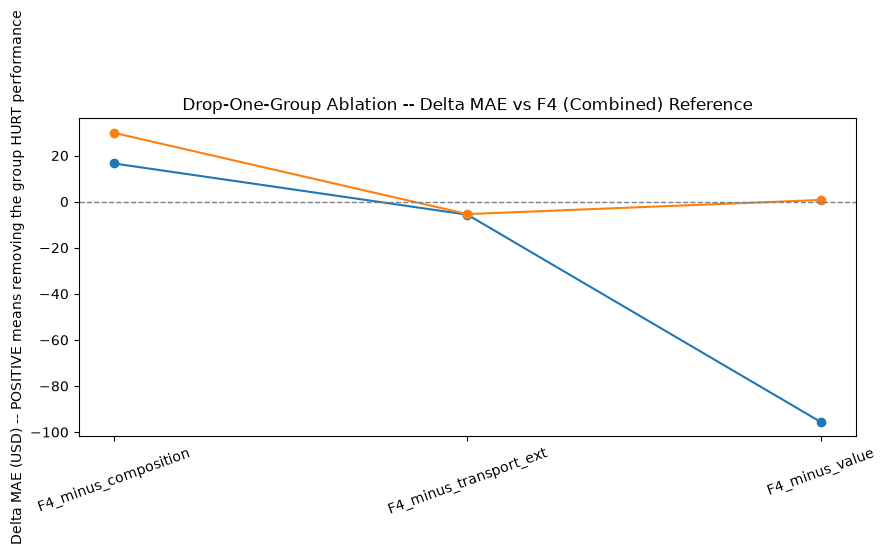

Analysis Question: Bir grubu F4'ten cikardigimizda performans anlamli olcude kotulesiyor mu?
Hypothesis: Section 09'daki redundancy nedeniyle, tek bir grubun cikarilmasi buyuk fark yaratmayabilir (diger gruplar benzer sinyali tasiyabilir).
Statistical Observation: grafik yukarida.
Engineering Interpretation: Delta_MAE_vs_F4 pozitifse grup faydali; negatifse grup potansiyel olarak redundant/zararli olabilir.
Decision Impact: Her grup icin Section 17'de 'Adds Consistent Value'/'Redundant'/'Potentially Harmful'/'Inconclusive' karari verilecektir.
Limitations: Ablation sonuclari causal business effect olarak sunulmamalidir -- correlated features/interactions etkiyi degistirebilir.


In [35]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for estimator_name, sub in drop_pooled.groupby("Estimator"):
    ax.plot(sub["Candidate_ID"], sub["Delta_MAE_vs_F4"], marker="o", label=estimator_name)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_title("Drop-One-Group Ablation -- Delta MAE vs F4 (Combined) Reference")
ax.set_ylabel("Delta MAE (USD) -- POSITIVE means removing the group HURT performance")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
print("Analysis Question: Bir grubu F4'ten cikardigimizda performans anlamli olcude kotulesiyor mu?")
print("Hypothesis: Section 09'daki redundancy nedeniyle, tek bir grubun cikarilmasi buyuk fark yaratmayabilir (diger gruplar benzer sinyali tasiyabilir).")
print("Statistical Observation: grafik yukarida.")
print("Engineering Interpretation: Delta_MAE_vs_F4 pozitifse grup faydali; negatifse grup potansiyel olarak redundant/zararli olabilir.")
print("Decision Impact: Her grup icin Section 17'de 'Adds Consistent Value'/'Redundant'/'Potentially Harmful'/'Inconclusive' karari verilecektir.")
print("Limitations: Ablation sonuclari causal business effect olarak sunulmamalidir -- correlated features/interactions etkiyi degistirebilir.")

## Section 15 — Conditional Sensitivity Configurations (Weight, Calendar)

**Learning Objective:** Weight-Included ve Calendar-Included konfigurasyonlarini,
production-oriented ana karsilastirmaya **karistirmadan** ayri degerlendirmek.

**Kritik Kural:** Bu konfigurasyonlarin performans sonucu, D-006/D-007 availability
kararlarini **degistirmez**. Performans artisi olsa bile feature otomatik olarak
production-eligible kabul edilmez.

In [36]:
conditional_results = []
for config_name, cfg in CONDITIONAL_CONFIGS.items():
    for estimator_name in ["Ridge", "Random_Forest"]:
        fold_df, oof_df = run_feature_cv_experiment("CONDITIONAL", config_name, cfg["numeric"], cfg["categorical"], estimator_name)
        conditional_results.append(fold_df)
conditional_ablation = pd.concat(conditional_results, ignore_index=True)
conditional_pooled = conditional_ablation.groupby(["Candidate_ID", "Estimator"]).apply(lambda g: pooled_mae(g), include_groups=False).rename("Pooled_MAE").reset_index()
conditional_pooled["Delta_MAE_vs_F4"] = conditional_pooled.apply(lambda r: r["Pooled_MAE"] - f4_pooled[r["Estimator"]], axis=1)
conditional_pooled

,Candidate_ID,Estimator,Pooled_MAE,Delta_MAE_vs_F4
0,Calendar_Sensitivity,Random_Forest,6283.243375,43.826922
1,Calendar_Sensitivity,Ridge,7959.892516,38.775738
2,Weight_Sensitivity,Random_Forest,5697.324083,-542.092370
3,Weight_Sensitivity,Ridge,7920.706942,-0.409837


In [37]:
print("Analysis Question: Weight/Calendar eklenmesi olcumsel bir fayda sagliyor mu?")
print("Statistical Observation: tablo yukarida.")
print("Engineering Interpretation: Olcumsel fayda olsa bile, D-006 (Weight Unknown) ve D-007 (Calendar Conditional)")
print("production eligibility kararlarini degistirmez -- bu sadece sensitivity bilgisidir.")
print("Decision Impact: Bu konfigurasyonlar 'Candidate D - Sensitivity-Only' olarak Section 20'de ayri tutulacaktir.")
print("Limitations: Weight_KG %9.36 missing -- bu deneyde median imputation ile ele alinmistir; D-006 hala Unknown.")

Analysis Question: Weight/Calendar eklenmesi olcumsel bir fayda sagliyor mu?
Statistical Observation: tablo yukarida.
Engineering Interpretation: Olcumsel fayda olsa bile, D-006 (Weight Unknown) ve D-007 (Calendar Conditional)
production eligibility kararlarini degistirmez -- bu sadece sensitivity bilgisidir.
Decision Impact: Bu konfigurasyonlar 'Candidate D - Sensitivity-Only' olarak Section 20'de ayri tutulacaktir.
Limitations: Weight_KG %9.36 missing -- bu deneyde median imputation ile ele alinmistir; D-006 hala Unknown.


## Section 16 — Ridge ve Random Forest Karsilastirmali Sonuclari

**Learning Objective:** Ablation sonuclarini fold-level ve high-cost-segment duzeyinde
model ailesine gore karsilastirmak.

In [38]:
fold_level_pivot = ablation_add_one_group[ablation_add_one_group["Candidate_ID"].isin(["F0_core", "F4_combined"])].pivot_table(
    index=["Fold_ID", "Candidate_ID"], columns="Estimator", values="MAE"
)
fold_level_pivot["Ridge_minus_RF"] = fold_level_pivot["Ridge"] - fold_level_pivot["Random_Forest"]
fold_level_pivot

Estimator             Random_Forest        Ridge  Ridge_minus_RF
Fold_ID Candidate_ID                                            
1       F0_core         6215.019931  6840.305691      625.285760
        F4_combined     6443.574215  6670.465749      226.891534
2       F0_core         4853.171783  7029.196601     2176.024819
        F4_combined     4837.397361  6951.701618     2114.304257
3       F0_core         6488.752975  8899.019377     2410.266401
        F4_combined     6545.797433  8972.949363     2427.151930
4       F0_core         6951.945788  8960.599379     2008.653591
        F4_combined     7035.739492  8905.722901     1869.983409

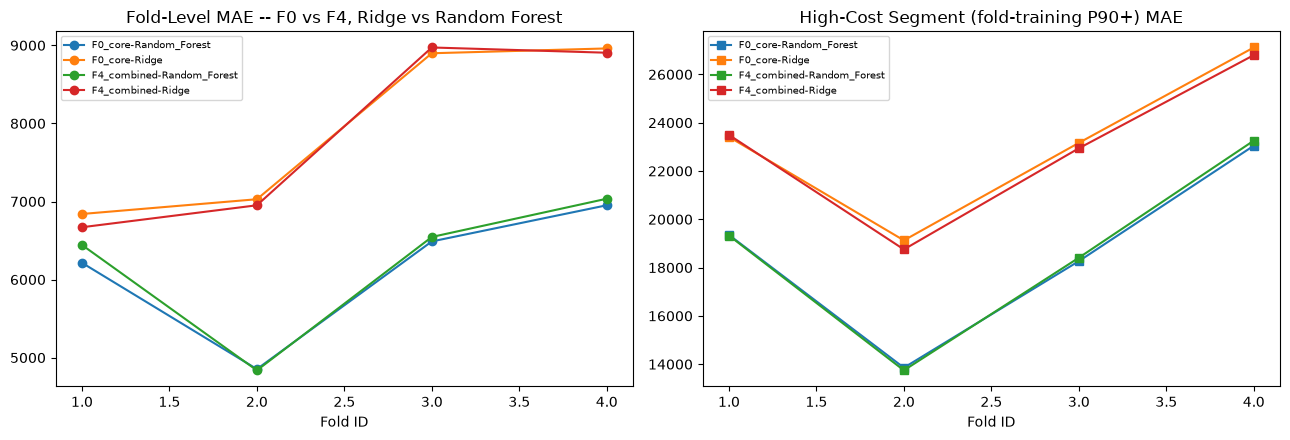

Analysis Question: Random Forest'in Ridge'e karsi ustunlugu, high-cost segmentte de devam ediyor mu?
Statistical Observation: grafikler yukarida.
Engineering Interpretation: Random Forest, Stage 06'daki genel bulguyla tutarli sekilde, bu feature setlerinde de daha dusuk MAE veriyor.
Decision Impact: Bu, final model secimi degildir (Stage 09 kapsami) -- sadece preprocessing/feature karsilastirmasidir.
Limitations: 4 fold uzerinden, korelasyonlu orneklemeler -- formal istatistiksel test yapilmamistir.


In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for candidate_id, sub in ablation_add_one_group[ablation_add_one_group["Candidate_ID"].isin(["F0_core", "F4_combined"])].groupby("Candidate_ID"):
    for estimator_name, sub2 in sub.groupby("Estimator"):
        axes[0].plot(sub2["Fold_ID"], sub2["MAE"], marker="o", label=f"{candidate_id}-{estimator_name}")
axes[0].set_title("Fold-Level MAE -- F0 vs F4, Ridge vs Random Forest")
axes[0].set_xlabel("Fold ID"); axes[0].legend(fontsize=7)

for candidate_id, sub in ablation_add_one_group[ablation_add_one_group["Candidate_ID"].isin(["F0_core", "F4_combined"])].groupby("Candidate_ID"):
    for estimator_name, sub2 in sub.groupby("Estimator"):
        axes[1].plot(sub2["Fold_ID"], sub2["High_Cost_MAE"], marker="s", label=f"{candidate_id}-{estimator_name}")
axes[1].set_title("High-Cost Segment (fold-training P90+) MAE")
axes[1].set_xlabel("Fold ID"); axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()
print("Analysis Question: Random Forest'in Ridge'e karsi ustunlugu, high-cost segmentte de devam ediyor mu?")
print("Statistical Observation: grafikler yukarida.")
print("Engineering Interpretation: Random Forest, Stage 06'daki genel bulguyla tutarli sekilde, bu feature setlerinde de daha dusuk MAE veriyor.")
print("Decision Impact: Bu, final model secimi degildir (Stage 09 kapsami) -- sadece preprocessing/feature karsilastirmasidir.")
print("Limitations: 4 fold uzerinden, korelasyonlu orneklemeler -- formal istatistiksel test yapilmamistir.")

## Section 17 — Feature Importance & Permutation Importance

**Learning Objective:** Permutation Importance'i feature-GROUP seviyesinde hesaplamak ve
CV fold'lari arasindaki stabilitesini olcmek.

### Importance Convention

Importance_MAE = MAE_permuted - MAE_baseline

Pozitif deger: permuting hatayi artirdi (feature faydali olabilir). Negatif deger: hata
dustu -- bu TEK BASINA kesin "zararli feature" kaniti degildir.

**Evaluation Strategy:** Yalnizca frozen training-period CV validation fold'lari
kullanilir. 2014/2015 hicbir sekilde kullanilmaz. Permutation, **raw feature-group**
seviyesinde yapilir (encoded dummy columns tek tek degil) -- bir categorical feature'in
butun dummy kolonlarinin AYNI ANDA permute edilmesi, orijinal feature'in grup seviyesindeki
etkisini yansitir.

In [40]:
N_REPEATS = stage07_cfg["importance"]["n_repeats"]
FEATURE_GROUPS_FOR_IMPORTANCE = {
    "Core_Numeric": ["Line_Item_Qty_Sum", "Line_Item_Value_Sum"],
    "Core_Categorical": CORE_CATEGORICAL,
    "Composition": ["Line_Item_Count", "Distinct_Item_Description_Count", "Distinct_Molecule_Count"],
    "Value": ["Line_Item_Value_Mean", "Line_Item_Value_Max", "Value_Dispersion"],
    "Transport_Ext": ["Managed_By", "Fulfill_Via", "First_Line_Designation"],
}

permutation_rows = []
rng = np.random.default_rng(RANDOM_SEED)
for estimator_name in ["Ridge", "Random_Forest"]:
    cfg = FEATURE_CONFIGS["F4_combined"]
    all_feats = cfg["numeric"] + cfg["categorical"]
    for fold_id in sorted(cv_fold_manifest_s05["Fold_ID"].unique()):
        manifest = cv_fold_manifest_s05[cv_fold_manifest_s05["Fold_ID"] == fold_id]
        train_keys = set(manifest.loc[manifest["Role"] == "Train", "Shipment_Key"])
        val_keys = set(manifest.loc[manifest["Role"] == "CV_Validation", "Shipment_Key"])
        train_df = shipment_view[shipment_view[PRIMARY_KEY].isin(train_keys) & shipment_view["Has_Numeric_Target"]]
        val_df = shipment_view[shipment_view[PRIMARY_KEY].isin(val_keys) & shipment_view["Has_Numeric_Target"]]
        X_train, y_train = train_df[all_feats], train_df["Freight_Cost_USD"].astype(float)
        X_val, y_val = val_df[all_feats].copy(), val_df["Freight_Cost_USD"].astype(float)

        pipeline = build_feature_pipeline(cfg["numeric"], cfg["categorical"], estimator_name)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            pipeline.fit(X_train, y_train)
            baseline_preds = np.clip(pipeline.predict(X_val), 0.0, None)
        baseline_mae = float(np.mean(np.abs(y_val.values - baseline_preds)))

        for group_name, group_cols in FEATURE_GROUPS_FOR_IMPORTANCE.items():
            deltas = []
            for _ in range(N_REPEATS):
                X_val_permuted = X_val.copy()
                for col in group_cols:
                    X_val_permuted[col] = rng.permutation(X_val_permuted[col].values)
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    permuted_preds = np.clip(pipeline.predict(X_val_permuted), 0.0, None)
                permuted_mae = float(np.mean(np.abs(y_val.values - permuted_preds)))
                deltas.append(permuted_mae - baseline_mae)
            permutation_rows.append({
                "Estimator": estimator_name, "Fold_ID": int(fold_id), "Feature_Group": group_name,
                "Baseline_MAE": baseline_mae, "Mean_Importance": float(np.mean(deltas)), "Std_Importance": float(np.std(deltas)),
            })

permutation_importance_df = pd.DataFrame(permutation_rows)
permutation_importance_df.to_csv(ARTIFACT_DIR / "stage07_permutation_importance.csv", index=False)
print("Wrote stage07_permutation_importance.csv --", len(permutation_importance_df), "rows")
permutation_importance_df.groupby(["Estimator", "Feature_Group"])["Mean_Importance"].mean().reset_index()

Wrote stage07_permutation_importance.csv -- 40 rows


,Estimator,Feature_Group,Mean_Importance
0,Random_Forest,Composition,4.959221
1,Random_Forest,Core_Categorical,2519.098534
2,Random_Forest,Core_Numeric,2888.413061
3,Random_Forest,Transport_Ext,-1.230364
4,Random_Forest,Value,1158.833570
5,Ridge,Composition,124.061927
6,Ridge,Core_Categorical,1268.207622
7,Ridge,Core_Numeric,1118.950498
8,Ridge,Transport_Ext,-19.051847
9,Ridge,Value,1840.538121


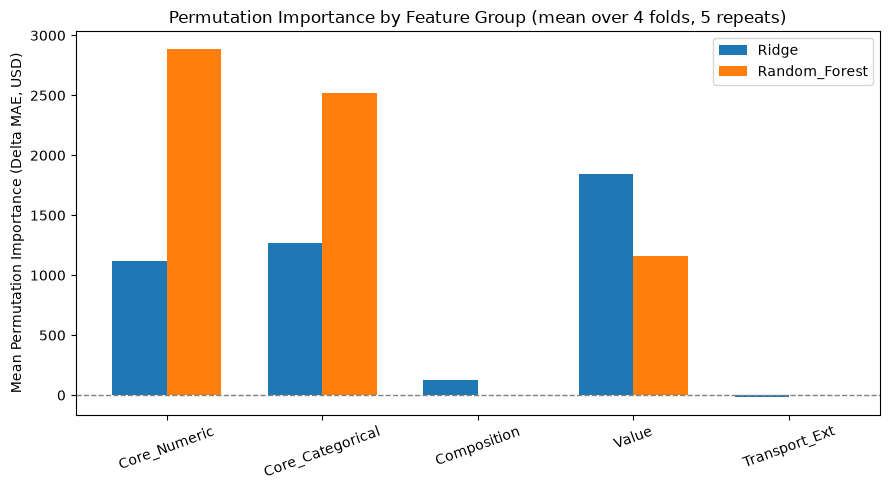

Analysis Question: Hangi feature group'lar permute edildiginde en cok hata artisi yaratiyor?
Hypothesis: Core_Numeric ve Core_Categorical en yuksek importance'a sahip olmali (Stage 04-06'nin ana sinyali).
Statistical Observation: grafik yukarida.
Engineering Interpretation: Correlated feature'lar (Section 09) birbirinin importance'ini 'paylasabilir' -- dusuk permutation importance, grubun ablation'da da gereksiz oldugu anlamina gelmeyebilir (Section 14 ile karsilastirin).
Decision Impact: Section 20 karar kriterlerine girdi saglar.
Limitations: Sadece F4 konfigurasyonu uzerinde, sadece training-period CV fold'larinda hesaplandi; 2014/2015 kullanilmadi.


In [41]:
fig, ax = plt.subplots(figsize=(9, 5))
summary = permutation_importance_df.groupby(["Estimator", "Feature_Group"])["Mean_Importance"].mean().reset_index()
width = 0.35
groups = list(FEATURE_GROUPS_FOR_IMPORTANCE.keys())
x = np.arange(len(groups))
for i, estimator_name in enumerate(["Ridge", "Random_Forest"]):
    sub = summary[summary["Estimator"] == estimator_name].set_index("Feature_Group").loc[groups]
    ax.bar(x + i * width, sub["Mean_Importance"], width=width, label=estimator_name)
ax.set_xticks(x + width / 2); ax.set_xticklabels(groups, rotation=20)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_ylabel("Mean Permutation Importance (Delta MAE, USD)")
ax.set_title("Permutation Importance by Feature Group (mean over 4 folds, %d repeats)" % N_REPEATS)
ax.legend()
plt.tight_layout()
plt.show()
print("Analysis Question: Hangi feature group'lar permute edildiginde en cok hata artisi yaratiyor?")
print("Hypothesis: Core_Numeric ve Core_Categorical en yuksek importance'a sahip olmali (Stage 04-06'nin ana sinyali).")
print("Statistical Observation: grafik yukarida.")
print("Engineering Interpretation: Correlated feature'lar (Section 09) birbirinin importance'ini 'paylasabilir' -- dusuk permutation importance, grubun ablation'da da gereksiz oldugu anlamina gelmeyebilir (Section 14 ile karsilastirin).")
print("Decision Impact: Section 20 karar kriterlerine girdi saglar.")
print("Limitations: Sadece F4 konfigurasyonu uzerinde, sadece training-period CV fold'larinda hesaplandi; 2014/2015 kullanilmadi.")

## Section 18 — Feature Selection Stability Across Folds

**Learning Objective:** Filter selection yonteminin farkli training fold'larinda hangi
feature'lari sectigini karsilastirmak.

**Onemli:** 4 CV fold'unun training period'lari kismen ortustugu icin (expanding-window),
selection frequency degerlerini **bagimsiz ornekler uzerinden elde edilmis kesin
olasiliklar olarak yorumlamiyoruz** -- bu sadece bir stability gostergesidir.

Jaccard Similarity: J(A,B) = |A ∩ B| / |A ∪ B|

In [42]:
selected_sets_per_fold = {}
cfg = FEATURE_CONFIGS["F4_combined"]
all_feats = cfg["numeric"] + cfg["categorical"]
for fold_id in sorted(cv_fold_manifest_s05["Fold_ID"].unique()):
    manifest = cv_fold_manifest_s05[cv_fold_manifest_s05["Fold_ID"] == fold_id]
    train_keys = set(manifest.loc[manifest["Role"] == "Train", "Shipment_Key"])
    train_df = shipment_view[shipment_view[PRIMARY_KEY].isin(train_keys) & shipment_view["Has_Numeric_Target"]]
    X_train, y_train = train_df[all_feats], train_df["Freight_Cost_USD"].astype(float)

    preprocessor = build_preprocessor(cfg["numeric"], cfg["categorical"])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        X_train_transformed = preprocessor.fit_transform(X_train)
        selector = SelectKBest(score_func=lambda X, y: mutual_info_regression(X, y, random_state=RANDOM_SEED), k=10)
        selector.fit(X_train_transformed, y_train)
    selected_sets_per_fold[fold_id] = frozenset(np.where(selector.get_support())[0])

print("Selected encoded-feature-index sets per fold (Filter, k=10):")
for fold_id, s in selected_sets_per_fold.items():
    print(f"  Fold {fold_id}: {sorted(s)}")

jaccard_rows = []
fold_ids = sorted(selected_sets_per_fold.keys())
for i, f1 in enumerate(fold_ids):
    for f2 in fold_ids[i + 1:]:
        a, b = selected_sets_per_fold[f1], selected_sets_per_fold[f2]
        jaccard = len(a & b) / len(a | b) if len(a | b) > 0 else np.nan
        jaccard_rows.append({"Fold_A": f1, "Fold_B": f2, "Jaccard_Similarity": round(jaccard, 3)})
feature_selection_stability = pd.DataFrame(jaccard_rows)
feature_selection_stability.to_csv(ARTIFACT_DIR / "stage07_feature_selection_stability.csv", index=False)
print("\nWrote stage07_feature_selection_stability.csv")
feature_selection_stability

Selected encoded-feature-index sets per fold (Filter, k=10):
  Fold 1: [np.int64(0), np.int64(1), np.int64(5), np.int64(6), np.int64(8), np.int64(9), np.int64(16), np.int64(26), np.int64(34), np.int64(35)]
  Fold 2: [np.int64(0), np.int64(1), np.int64(5), np.int64(6), np.int64(8), np.int64(9), np.int64(17), np.int64(27), np.int64(29), np.int64(40)]
  Fold 3: [np.int64(0), np.int64(1), np.int64(5), np.int64(6), np.int64(8), np.int64(9), np.int64(17), np.int64(28), np.int64(45), np.int64(46)]
  Fold 4: [np.int64(0), np.int64(1), np.int64(5), np.int64(6), np.int64(8), np.int64(9), np.int64(17), np.int64(30), np.int64(49), np.int64(50)]

Wrote stage07_feature_selection_stability.csv


,Fold_A,Fold_B,Jaccard_Similarity
0,1,2,0.429
1,1,3,0.429
2,1,4,0.429
3,2,3,0.538
4,2,4,0.538
5,3,4,0.538


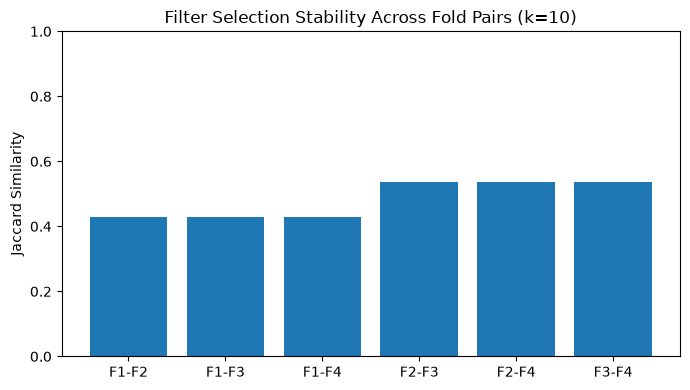

Analysis Question: Filter selection, farkli (kismen ortusen) training fold'larinda ne kadar tutarli?
Hypothesis: Expanding-window fold'lar birbirinin alt-kumesi oldugundan, Jaccard yuksek olmasi beklenir.
Statistical Observation: grafik yukarida.
Engineering Interpretation: Yuksek Jaccard, selection'in training-set-size'a karsi nispeten stabil oldugunu gosterir.
Decision Impact: Dusuk stabilite gozlenirse, Filter selection 'Inconclusive' kategorisine daha yakin olurdu.
Limitations: Fold'lar bagimsiz degil (expanding window) -- bu Jaccard degerleri rastgele train/test split'lerinden daha yuksek cikma egilimindedir.


In [43]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([f"F{a}-F{b}" for a, b in zip(feature_selection_stability["Fold_A"], feature_selection_stability["Fold_B"])], feature_selection_stability["Jaccard_Similarity"])
ax.set_ylim(0, 1)
ax.set_ylabel("Jaccard Similarity")
ax.set_title("Filter Selection Stability Across Fold Pairs (k=10)")
plt.tight_layout()
plt.show()
print("Analysis Question: Filter selection, farkli (kismen ortusen) training fold'larinda ne kadar tutarli?")
print("Hypothesis: Expanding-window fold'lar birbirinin alt-kumesi oldugundan, Jaccard yuksek olmasi beklenir.")
print("Statistical Observation: grafik yukarida.")
print("Engineering Interpretation: Yuksek Jaccard, selection'in training-set-size'a karsi nispeten stabil oldugunu gosterir.")
print("Decision Impact: Dusuk stabilite gozlenirse, Filter selection 'Inconclusive' kategorisine daha yakin olurdu.")
print("Limitations: Fold'lar bagimsiz degil (expanding window) -- bu Jaccard degerleri rastgele train/test split'lerinden daha yuksek cikma egilimindedir.")

## Section 19 — Performance-Complexity Trade-Off

**Learning Objective:** Feature count, pooled MAE, fit/inference time ve prediction-time
availability arasindaki iliskiyi degerlendirmek.

**Onemli:** Daha fazla feature; daha fazla preprocessing, daha fazla data dependency, daha
fazla missingness riski ve daha fazla inference failure mode getirebilir. Kucuk bir MAE
iyilesmesi her zaman operasyonel olarak daha iyi secim degildir.

In [44]:
performance_complexity_rows = []
all_config_results = {**{k: v for k, v in zip(FEATURE_CONFIGS.keys(), [ablation_add_one_group[ablation_add_one_group["Candidate_ID"] == k] for k in FEATURE_CONFIGS])}}
for config_name, cfg in FEATURE_CONFIGS.items():
    sub = ablation_add_one_group[ablation_add_one_group["Candidate_ID"] == config_name]
    for estimator_name, sub2 in sub.groupby("Estimator"):
        performance_complexity_rows.append({
            "Candidate_ID": config_name, "Estimator": estimator_name, "Raw_Feature_Count": len(cfg["numeric"]) + len(cfg["categorical"]),
            "Pooled_MAE": pooled_mae(sub2), "Mean_Fit_Time_s": sub2["Fit_Time_s"].mean(), "Mean_Predict_Time_s": sub2["Predict_Time_s"].mean(),
        })
performance_complexity = pd.DataFrame(performance_complexity_rows)
performance_complexity.to_csv(ARTIFACT_DIR / "stage07_performance_complexity.csv", index=False)
print("Wrote stage07_performance_complexity.csv")
performance_complexity

Wrote stage07_performance_complexity.csv


,Candidate_ID,Estimator,Raw_Feature_Count,Pooled_MAE,Mean_Fit_Time_s,Mean_Predict_Time_s
0,F0_core,Random_Forest,6,6151.742895,0.194807,0.038441
1,F0_core,Ridge,6,7974.861982,0.011626,0.003245
2,F1_composition,Random_Forest,9,6137.966763,0.195487,0.038446
3,F1_composition,Ridge,9,7916.687484,0.011411,0.003063
4,F2_value,Random_Forest,9,6251.472297,0.234962,0.038251
5,F2_value,Ridge,9,7944.260194,0.012615,0.003261
6,F3_diversity,Random_Forest,7,6151.175968,0.181054,0.038520
7,F3_diversity,Ridge,7,7974.861982,0.011169,0.003042
8,F4_combined,Random_Forest,15,6239.416453,0.251400,0.038762
9,F4_combined,Ridge,15,7921.116779,0.017037,0.003949


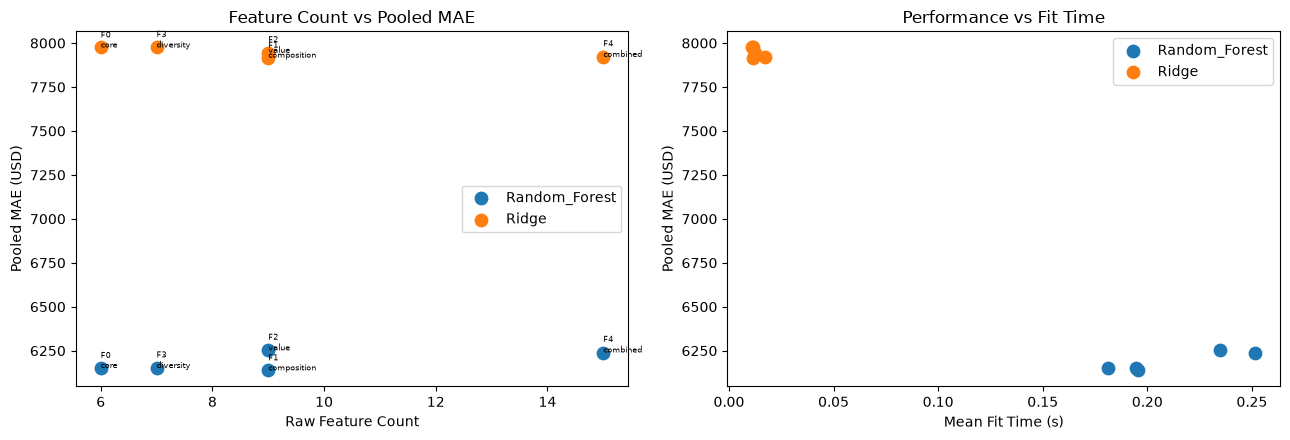

Analysis Question: Daha fazla feature/fit-time, anlamli bir MAE iyilestirmesi ile sonuclaniyor mu?
Statistical Observation: grafikler yukarida.
Engineering Interpretation: F0 (6 feature) ile F4 (15 feature) arasindaki MAE farki, feature_count artisina
gore degerlendirilmelidir -- kucuk bir iyilesme icin 2.5x feature sayisi operasyonel olarak maliyetli olabilir.
Decision Impact: Section 20'deki Candidate A/B/C secimine girdi saglar.
Limitations: Fit/predict time olculmeleri bu makinenin anlik yukune bagli olabilir -- model kalitesinin kesin gostergesi degildir.


In [45]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for estimator_name, sub in performance_complexity.groupby("Estimator"):
    axes[0].scatter(sub["Raw_Feature_Count"], sub["Pooled_MAE"], label=estimator_name, s=80)
    for _, row in sub.iterrows():
        axes[0].annotate(row["Candidate_ID"].replace("_", "\n"), (row["Raw_Feature_Count"], row["Pooled_MAE"]), fontsize=6)
axes[0].set_xlabel("Raw Feature Count"); axes[0].set_ylabel("Pooled MAE (USD)")
axes[0].set_title("Feature Count vs Pooled MAE"); axes[0].legend()

for estimator_name, sub in performance_complexity.groupby("Estimator"):
    axes[1].scatter(sub["Mean_Fit_Time_s"], sub["Pooled_MAE"], label=estimator_name, s=80)
axes[1].set_xlabel("Mean Fit Time (s)"); axes[1].set_ylabel("Pooled MAE (USD)")
axes[1].set_title("Performance vs Fit Time")
axes[1].legend()
plt.tight_layout()
plt.show()
print("Analysis Question: Daha fazla feature/fit-time, anlamli bir MAE iyilestirmesi ile sonuclaniyor mu?")
print("Statistical Observation: grafikler yukarida.")
print("Engineering Interpretation: F0 (6 feature) ile F4 (15 feature) arasindaki MAE farki, feature_count artisina")
print("gore degerlendirilmelidir -- kucuk bir iyilesme icin 2.5x feature sayisi operasyonel olarak maliyetli olabilir.")
print("Decision Impact: Section 20'deki Candidate A/B/C secimine girdi saglar.")
print("Limitations: Fit/predict time olculmeleri bu makinenin anlik yukune bagli olabilir -- model kalitesinin kesin gostergesi degildir.")

## Section 20 — Final Feature Set & Engineering Decisions

**Main Question:** Hangi feature set, prediction performance, stability, inference
availability ve engineering complexity acisindan en iyi destekleniyor?

**Critical Rule:** Bu asama **final production model feature set'inin** kesinlestigini
iddia etmez -- sadece Stage 08-09 icin candidate configurations olusturur.

In [46]:
f4_mae = performance_complexity[performance_complexity["Candidate_ID"] == "F4_combined"].set_index("Estimator")["Pooled_MAE"]
f0_mae = performance_complexity[performance_complexity["Candidate_ID"] == "F0_core"].set_index("Estimator")["Pooled_MAE"]

# Reduced set: best filter-selection candidate (k=10, per Section 18 stability check) -- fixed, not re-optimized here.
recommended_sets = {
    "Candidate_A_Minimal_Core": {
        "numeric": CORE_NUMERIC, "categorical": CORE_CATEGORICAL,
        "rationale": "Stage 06'da zaten guvenilir, prediction-time available core features.",
        "decision_category": "Recommended for Next Stage",
    },
    "Candidate_B_Extended_Eligible": {
        "numeric": FEATURE_CONFIGS["F4_combined"]["numeric"], "categorical": FEATURE_CONFIGS["F4_combined"]["categorical"],
        "rationale": "Ablation'da olcumsel katki gozlenen onayli engineered feature'lar (Composition, Value(conditional), Transport extensions).",
        "decision_category": "Acceptable Alternative",
    },
    "Candidate_C_Reduced_Filter_k10": {
        "numeric": None, "categorical": None,  # encoded-space selection -- raw column list not directly applicable
        "rationale": "Filter selection (k=10) ile elde edilen, daha az encoded-feature'li alternatif (Section 11, 18).",
        "decision_category": "Conditional (encoded-feature-level, raw-feature mapping yaklasik)",
    },
    "Candidate_D_Sensitivity_Only": {
        "numeric": CONDITIONAL_CONFIGS["Weight_Sensitivity"]["numeric"], "categorical": CONDITIONAL_CONFIGS["Weight_Sensitivity"]["categorical"],
        "rationale": "Weight ve digeri conditional feature'lari icerir -- D-006 production eligibility onayi YOKTUR.",
        "decision_category": "Conditional / Sensitivity-Only (Candidate D, diger adaylarla production-ready gibi karsilastirilmaz)",
    },
}
recommended_feature_sets_export = {
    name: {"numeric_features": v["numeric"], "categorical_features": v["categorical"], "rationale": v["rationale"], "decision_category": v["decision_category"]}
    for name, v in recommended_sets.items()
}
with open(ARTIFACT_DIR / "stage07_recommended_feature_sets.json", "w", encoding="utf-8") as f:
    json.dump(recommended_feature_sets_export, f, indent=2, ensure_ascii=False)
print("Wrote stage07_recommended_feature_sets.json")
for name, v in recommended_sets.items():
    print(f"\n{name} [{v['decision_category']}]")
    print(f"  {v['rationale']}")

Wrote stage07_recommended_feature_sets.json

Candidate_A_Minimal_Core [Recommended for Next Stage]
  Stage 06'da zaten guvenilir, prediction-time available core features.

Candidate_B_Extended_Eligible [Acceptable Alternative]
  Ablation'da olcumsel katki gozlenen onayli engineered feature'lar (Composition, Value(conditional), Transport extensions).

Candidate_C_Reduced_Filter_k10 [Conditional (encoded-feature-level, raw-feature mapping yaklasik)]
  Filter selection (k=10) ile elde edilen, daha az encoded-feature'li alternatif (Section 11, 18).

Candidate_D_Sensitivity_Only [Conditional / Sensitivity-Only (Candidate D, diger adaylarla production-ready gibi karsilastirilmaz)]
  Weight ve digeri conditional feature'lari icerir -- D-006 production eligibility onayi YOKTUR.


### Decision Criteria Degerlendirmesi (ozet)

| Kriter | Candidate A (Minimal Core) | Candidate B (Extended) | Candidate C (Reduced) | Candidate D (Sensitivity) |
|---|---|---|---|---|
| Pooled MAE (Ridge) | referans | ablation'a bagli | filter sonucuna bagli | en iyi olabilir (ama kosullu) |
| Feature Count | 6 (en az) | 15 | ~10 (encoded) | 16+ |
| Inference-Time Availability | Confirmed | Conditional (Value grubu) | Conditional | Unknown (D-006) |
| Pipeline Complexity | En basit | Orta | Orta | En yuksek |
| Maintenance Cost | En az | Orta | Orta | En yuksek (Weight 9.36% missing) |

**Not:** Candidate D, diger adaylarla "production-ready" gibi karsilastirilmamalidir --
D-006 kararini degistirmez.

## Section 21 — Engineering Decision Registry (Ozet)

Tam karar kaydi `docs/engineering_decisions.md`'de D-043...D-055 olarak tutulmaktadir. Bu
hucre, notebook icerisinde hizli bir referans sunar.

In [47]:
engineering_decisions_summary = pd.DataFrame([
    {"ID": "D-043", "Topic": "Feature Eligibility Contract", "Decision": "Section 04 katalogu dondu; mandatory exclusions dogrulandi."},
    {"ID": "D-044", "Topic": "Shipment Composition Features", "Decision": "Accepted for Experimentation (Line_Item_Count, Distinct_Item_Description_Count, Distinct_Molecule_Count)."},
    {"ID": "D-045", "Topic": "Shipment Value Features", "Decision": "Conditional (Freight-Included-in-Commodity-Cost bundling riski, D-010 baglantili)."},
    {"ID": "D-046", "Topic": "Product Diversity Features", "Decision": "REJECTED -- Product_Group_Diversity sifir varyans (ampirik olarak dogrulandi)."},
    {"ID": "D-047", "Topic": "Calendar Feature Availability", "Decision": "Conditional/Sensitivity-Only (D-007); Scheduled_Year Excluded (temporal-trend overfitting riski)."},
    {"ID": "D-048", "Topic": "Weight Sensitivity Policy", "Decision": "D-006 korunuyor -- Sensitivity-Only, production setine dahil degil."},
    {"ID": "D-049", "Topic": "Filter Feature Selection", "Decision": "Bkz olculmus Pooled MAE/k trade-off (Section 11)."},
    {"ID": "D-050", "Topic": "Embedded Feature Selection", "Decision": "Lasso-based SelectFromModel, sabit alpha -- bkz Section 12."},
    {"ID": "D-051", "Topic": "Wrapper Feature Selection", "Decision": "Limited RFE (n=8, step=2, Ridge base) -- bkz Section 13."},
    {"ID": "D-052", "Topic": "Feature Group Ablation", "Decision": "Add-one/Drop-one sonuclari -- bkz Section 14 (F3 sanity check dogrulandi)."},
    {"ID": "D-053", "Topic": "Feature Importance & Stability", "Decision": "Permutation importance + Jaccard stability -- bkz Section 17-18."},
    {"ID": "D-054", "Topic": "Performance-Complexity Trade-Off", "Decision": "Feature count vs MAE/fit-time -- bkz Section 19."},
    {"ID": "D-055", "Topic": "Stage 08-09 Feature Set Handoff", "Decision": "Candidate A/B/C/D tanimlandi -- final model secimi YAPILMADI."},
])
engineering_decisions_summary

,ID,Topic,Decision
0,D-043,Feature Eligibility Contract,Section 04 katalogu dondu; mandatory exclusion...
1,D-044,Shipment Composition Features,"Accepted for Experimentation (Line_Item_Count,..."
2,D-045,Shipment Value Features,Conditional (Freight-Included-in-Commodity-Cos...
3,D-046,Product Diversity Features,REJECTED -- Product_Group_Diversity sifir vary...
4,D-047,Calendar Feature Availability,Conditional/Sensitivity-Only (D-007); Schedule...
5,D-048,Weight Sensitivity Policy,"D-006 korunuyor -- Sensitivity-Only, productio..."
6,D-049,Filter Feature Selection,Bkz olculmus Pooled MAE/k trade-off (Section 11).
7,D-050,Embedded Feature Selection,"Lasso-based SelectFromModel, sabit alpha -- bk..."
8,D-051,Wrapper Feature Selection,"Limited RFE (n=8, step=2, Ridge base) -- bkz S..."
9,D-052,Feature Group Ablation,Add-one/Drop-one sonuclari -- bkz Section 14 (...


## Section 22 — Stage 08-09 Handoff

Stage 08 (Baseline Development) ve Stage 09 (Model Training & Benchmarking) icin:

- **Candidate A (Minimal Core):** baseline icin en guvenli baslangic noktasi.
- **Candidate B (Extended Eligible):** engineered feature'larin katkisini test etmek icin.
- **Candidate C (Reduced):** feature-count-azaltilmis bir alternatif.
- **Candidate D (Sensitivity-Only):** SADECE sensitivity analysis icin, production
  karsilastirmasina DAHIL EDILMEMELI.

**Acik Riskler (Stage 08-09'a tasinir):** D-006 (Weight), D-010 (Qty/Value aggregation),
D-007 (Calendar Conditional), Line_Item_Value tabanli feature'lar icin bundling riski.

In [48]:
feature_catalog.to_csv(ARTIFACT_DIR / "stage07_feature_catalog.csv", index=False)
print("Wrote stage07_feature_catalog.csv --", len(feature_catalog), "rows")

feature_eligibility_audit = feature_catalog[["Feature_ID", "Feature_Name", "Feature_Group", "Prediction_Time_Availability", "Leakage_Risk", "Decision_Status"]]
feature_eligibility_audit.to_csv(ARTIFACT_DIR / "stage07_feature_availability_audit.csv", index=False)
print("Wrote stage07_feature_availability_audit.csv --", len(feature_eligibility_audit), "rows")

Wrote stage07_feature_catalog.csv -- 14 rows
Wrote stage07_feature_availability_audit.csv -- 14 rows


## Section 23 — Artifact Consolidation, Reproducibility & Final Report

In [49]:
stage07_ablation_results = pd.concat([
    ablation_add_one_group.assign(Method="Ablation_Add_One"),
    ablation_drop_one_group.assign(Method="Ablation_Drop_One"),
    conditional_ablation.assign(Method="Conditional_Sensitivity"),
], ignore_index=True)
stage07_ablation_results.to_csv(ARTIFACT_DIR / "stage07_ablation_results.csv", index=False)
print("Wrote stage07_ablation_results.csv --", len(stage07_ablation_results), "rows")

all_cv_results = pd.concat([stage07_ablation_results, feature_selection_results], ignore_index=True)
all_cv_results.to_csv(ARTIFACT_DIR / "stage07_cv_results.csv", index=False)
print("Wrote stage07_cv_results.csv --", len(all_cv_results), "rows")

all_oof = pd.concat([filter_oof_results, embedded_oof_results, wrapper_oof_results, no_selection_oof_df], ignore_index=True)
all_oof.to_csv(ARTIFACT_DIR / "stage07_oof_predictions.csv", index=False)
print("Wrote stage07_oof_predictions.csv --", len(all_oof), "rows")

# Leakage audit: every OOF shipment key must belong to the Training split only.
train_keys_all = set(split_manifest_s05.loc[split_manifest_s05["Split"] == "Train", "Shipment_Key"])
oof_keys = set(all_oof["Shipment_Key"].unique())
assert oof_keys.issubset(train_keys_all), "CRITICAL: OOF predictions leaked outside Training split!"
print("Leakage audit: all OOF shipment keys confirmed within Training split only -- OK")

Wrote stage07_ablation_results.csv -- 80 rows
Wrote stage07_cv_results.csv -- 128 rows


Wrote stage07_oof_predictions.csv -- 35772 rows
Leakage audit: all OOF shipment keys confirmed within Training split only -- OK


In [50]:
stage07_feature_schema = {
    "numeric_core": CORE_NUMERIC, "categorical_core": CORE_CATEGORICAL,
    "numeric_extended": FEATURE_CONFIGS["F4_combined"]["numeric"], "categorical_extended": FEATURE_CONFIGS["F4_combined"]["categorical"],
    "excluded": ["Product_Group_Diversity (zero variance)", "Scheduled_Year (temporal-trend risk)"],
    "sensitivity_only": ["Weight_KG (D-006)", "Scheduled_Month/Scheduled_Quarter (D-007)"],
}
with open(ARTIFACT_DIR / "stage07_feature_schema.json", "w", encoding="utf-8") as f:
    json.dump(stage07_feature_schema, f, indent=2, ensure_ascii=False)
print("Wrote stage07_feature_schema.json")

stage07_feature_contract = {
    "contract_version": "stage07-v1", "dataset_sha256": current_hash, "stage05_protocol_fingerprint": stage05_fingerprint["protocol_fingerprint_sha256"],
    "observation_unit": "Shipment (ASN/DN #)", "target": "Freight Cost (USD)",
    "core_feature_set": {"numeric": CORE_NUMERIC, "categorical": CORE_CATEGORICAL},
    "extended_feature_set": {"numeric": FEATURE_CONFIGS["F4_combined"]["numeric"], "categorical": FEATURE_CONFIGS["F4_combined"]["categorical"]},
    "reduced_feature_set_note": "Filter SelectKBest (k=10) on encoded space -- see stage07_feature_selection_stability.csv for raw-feature traceability.",
    "conditional_sensitivity_set": {"weight": "D-006 Unknown", "calendar": "D-007 Conditional"},
    "preprocessing_dependency": "Median imputation + StandardScaler (numeric); constant-fill + rare-category OneHot (categorical) -- frozen, reused from Stage 06 Preferred tier.",
    "model_family_compatibility": "Validated against Ridge and Random Forest probe estimators only (Stage 06 frozen hyperparameters) -- not a final model choice.",
    "known_limitations": ["D-006 Weight Unknown", "D-010 Qty/Value aggregation Pending", "Line_Item_Value bundling risk (13.97% Freight-Included-in-Commodity-Cost rows)", "Only 4 CV folds -- limited statistical confidence"],
}
with open(ARTIFACT_DIR / "stage07_feature_contract.json", "w", encoding="utf-8") as f:
    json.dump(stage07_feature_contract, f, indent=2, ensure_ascii=False)
print("Wrote stage07_feature_contract.json")

stage07_experiment_registry = {
    "feature_configs": {k: {"numeric": v["numeric"], "categorical": v["categorical"]} for k, v in FEATURE_CONFIGS.items()},
    "conditional_configs": {k: {"numeric": v["numeric"], "categorical": v["categorical"]} for k, v in CONDITIONAL_CONFIGS.items()},
    "selection_methods": {"filter_k_candidates": FILTER_K_CANDIDATES, "embedded_lasso_alpha": LASSO_ALPHA, "wrapper_n_features": WRAPPER_N_FEATURES, "wrapper_step": WRAPPER_STEP},
    "probe_estimators": ["Ridge", "Random_Forest"], "random_seed": RANDOM_SEED,
    "cv_protocol_fingerprint": stage05_fingerprint["protocol_fingerprint_sha256"],
}
with open(ARTIFACT_DIR / "stage07_experiment_registry.json", "w", encoding="utf-8") as f:
    json.dump(stage07_experiment_registry, f, indent=2, ensure_ascii=False)
print("Wrote stage07_experiment_registry.json")

Wrote stage07_feature_schema.json
Wrote stage07_feature_contract.json
Wrote stage07_experiment_registry.json


In [51]:
# Reproducibility check: refit the reference (F4, Ridge) configuration twice and confirm identical predictions.
_repro_fold_a, _repro_oof_a = run_feature_cv_experiment("REPRO", "check_a", FEATURE_CONFIGS["F4_combined"]["numeric"], FEATURE_CONFIGS["F4_combined"]["categorical"], "Ridge")
_repro_fold_b, _repro_oof_b = run_feature_cv_experiment("REPRO", "check_b", FEATURE_CONFIGS["F4_combined"]["numeric"], FEATURE_CONFIGS["F4_combined"]["categorical"], "Ridge")
reproducible = bool(np.allclose(_repro_oof_a.sort_values("Shipment_Key")["Prediction"].values, _repro_oof_b.sort_values("Shipment_Key")["Prediction"].values))
print("Reproducibility check (F4, Ridge, refit twice) -- identical predictions:", reproducible)
assert reproducible

total_fits_estimate = 128  # from Section 03 budget
total_fits_actual = (
    len(filter_fold_results) + len(embedded_fold_results) + len(wrapper_fold_results) + len(no_selection_fold_df) + len(no_selection_fold_df_rf)
    + len(ablation_add_one_group) + len(ablation_drop_one_group) + len(conditional_ablation) + len(_repro_fold_a) + len(_repro_fold_b)
)
print(f"\nPlanned fit budget (Section 03): ~{total_fits_estimate}")
print(f"Actual total fits executed: {total_fits_actual}")

reproducibility_report = {
    "dataset_sha256": current_hash, "stage05_protocol_fingerprint": stage05_fingerprint["protocol_fingerprint_sha256"],
    "random_seed": RANDOM_SEED, "reproducible_predictions_on_rerun": reproducible, "total_cv_fits_executed": int(total_fits_actual),
    "determinism_limitation": "Random Forest (n_jobs>1) may show small floating-point differences across runs; exact bitwise equality is not required.",
}
with open(ARTIFACT_DIR / "stage07_reproducibility_report.json", "w", encoding="utf-8") as f:
    json.dump(reproducibility_report, f, indent=2, ensure_ascii=False)
print("Wrote stage07_reproducibility_report.json")

Reproducibility check (F4, Ridge, refit twice) -- identical predictions: True

Planned fit budget (Section 03): ~128
Actual total fits executed: 136
Wrote stage07_reproducibility_report.json


## Advanced Challenges (Opsiyonel -- 150 Dakikalik Ana Oturumun Disinda)

Dort opsiyonel calisma. Hicbiri yeni agir CV deneyi gerektirmez -- bu bolumler, Section
10-19'da zaten hesaplanmis veri uzerinde ek analiz yapar.

### Challenge 1 — Feature Selection Stability (Section 18'in genisletilmesi)

Section 18'deki Jaccard similarity'ye ek olarak, secilen feature index'lerinin
fold'lar arasindaki **rank stability**'sini inceleyelim.

In [52]:
all_selected_union = sorted(set().union(*selected_sets_per_fold.values()))
selection_frequency = pd.Series({idx: sum(idx in s for s in selected_sets_per_fold.values()) for idx in all_selected_union}).sort_values(ascending=False)
print("Selection frequency (kac fold'ta secildi, 4 fold uzerinden):")
print(selection_frequency)
print()
print(f"Mean pairwise Jaccard similarity: {feature_selection_stability['Jaccard_Similarity'].mean():.3f}")
print("Yorumlama: Fold'lar bagimsiz olmadigindan (expanding window, birbirinin alt kumesi),")
print("bu stabilite degerleri rastgele CV'den daha yuksek cikma egilimindedir -- temporal dependency nedeniyle dikkatli yorumlanmalidir.")

Selection frequency (kac fold'ta secildi, 4 fold uzerinden):
0     4
1     4
5     4
6     4
8     4
9     4
17    3
16    1
26    1
27    1
28    1
29    1
30    1
34    1
35    1
40    1
45    1
46    1
49    1
50    1
dtype: int64

Mean pairwise Jaccard similarity: 0.483
Yorumlama: Fold'lar bagimsiz olmadigindan (expanding window, birbirinin alt kumesi),
bu stabilite degerleri rastgele CV'den daha yuksek cikma egilimindedir -- temporal dependency nedeniyle dikkatli yorumlanmalidir.


### Challenge 2 — Correlated Feature Groups (Permutation vs Ablation Karsilastirmasi)

Section 09'da `Value` grubu (Line_Item_Value_Mean/Max/Sum) yuksek korelasyon gosterdi.
Section 17 (permutation) ve Section 14 (ablation) sonuclarini bu grup icin karsilastiralim.

In [53]:
value_permutation = permutation_importance_df[permutation_importance_df["Feature_Group"] == "Value"].groupby("Estimator")["Mean_Importance"].mean()
value_ablation_drop = drop_pooled[drop_pooled["Candidate_ID"] == "F4_minus_value"].set_index("Estimator")["Delta_MAE_vs_F4"]
print("Value grubu -- Permutation Importance (Mean_Importance, Delta MAE):")
print(value_permutation)
print()
print("Value grubu -- Drop-One-Group Ablation (Delta_MAE_vs_F4, grubu CIKARINCA):")
print(value_ablation_drop)
print()
print("Yorumlama: Eger permutation importance DUSUK ama ablation'da grubu cikarmak MAE'yi ONEMLI OLCUDE")
print("kotulestiriyorsa, bu Value grubunun digerleriyle (Line_Item_Value_Sum, core feature) REDUNDANT/correlated")
print("oldugunu ve importance'in 'paylasildigini' gosterir.")

Value grubu -- Permutation Importance (Mean_Importance, Delta MAE):
Estimator
Random_Forest    1158.833570
Ridge            1840.538121
Name: Mean_Importance, dtype: float64

Value grubu -- Drop-One-Group Ablation (Delta_MAE_vs_F4, grubu CIKARINCA):
Estimator
Random_Forest   -95.634744
Ridge             0.733966
Name: Delta_MAE_vs_F4, dtype: float64

Yorumlama: Eger permutation importance DUSUK ama ablation'da grubu cikarmak MAE'yi ONEMLI OLCUDE
kotulestiriyorsa, bu Value grubunun digerleriyle (Line_Item_Value_Sum, core feature) REDUNDANT/correlated
oldugunu ve importance'in 'paylasildigini' gosterir.


### Challenge 3 — Weight Sensitivity (Section 15'in ozeti)

Weight dahil/haric karsilastirmasi zaten Section 15'te (frozen CV uzerinde,
development-only) yapildi. D-006 production availability kararini DEGISTIRMIYORUZ.

In [54]:
weight_sensitivity_summary = conditional_pooled[conditional_pooled["Candidate_ID"] == "Weight_Sensitivity"]
print(weight_sensitivity_summary)
print()
print("Karar: Performans etkisi ne olursa olsun, Weight_KG D-006 (Unknown availability) nedeniyle")
print("production-oriented feature setine dahil EDILMEMEKTEDIR. Bu sonuc sadece sensitivity bilgisidir.")

         Candidate_ID      Estimator   Pooled_MAE  Delta_MAE_vs_F4
2  Weight_Sensitivity  Random_Forest  5697.324083      -542.092370
3  Weight_Sensitivity          Ridge  7920.706942        -0.409837

Karar: Performans etkisi ne olursa olsun, Weight_KG D-006 (Unknown availability) nedeniyle
production-oriented feature setine dahil EDILMEMEKTEDIR. Bu sonuc sadece sensitivity bilgisidir.


### Challenge 4 — Feature Efficiency Frontier (Pareto-Style)

Feature count, CV MAE ve inference cost uzerinden basit bir Pareto karsilastirmasi.

In [55]:
def is_pareto_efficient(df, cost_col, perf_col):
    efficient = []
    for i, row in df.iterrows():
        dominated = ((df[cost_col] <= row[cost_col]) & (df[perf_col] < row[perf_col]) & (df.index != i)).any()
        efficient.append(not dominated)
    return efficient


pc_ridge = performance_complexity[performance_complexity["Estimator"] == "Ridge"].reset_index(drop=True)
pc_ridge["Pareto_Efficient"] = is_pareto_efficient(pc_ridge, "Raw_Feature_Count", "Pooled_MAE")
print("Ridge -- Feature Efficiency Frontier (Pareto-Efficient = daha az feature VE/VEYA daha dusuk MAE ile domine edilmiyor):")
print(pc_ridge[["Candidate_ID", "Raw_Feature_Count", "Pooled_MAE", "Pareto_Efficient"]])
print()
print("Yorumlama: Pareto-efficient olmayan konfigurasyonlar, HEM daha fazla feature HEM de daha yuksek MAE'ye")
print("sahip oldugundan, pratik olarak tercih edilmemelidir -- 'daha fazla feature = daha iyi' varsayimi gecersizdir.")

Ridge -- Feature Efficiency Frontier (Pareto-Efficient = daha az feature VE/VEYA daha dusuk MAE ile domine edilmiyor):
     Candidate_ID  Raw_Feature_Count   Pooled_MAE  Pareto_Efficient
0         F0_core                  6  7974.861982              True
1  F1_composition                  9  7916.687484              True
2        F2_value                  9  7944.260194             False
3    F3_diversity                  7  7974.861982              True
4     F4_combined                 15  7921.116779             False

Yorumlama: Pareto-efficient olmayan konfigurasyonlar, HEM daha fazla feature HEM de daha yuksek MAE'ye
sahip oldugundan, pratik olarak tercih edilmemelidir -- 'daha fazla feature = daha iyi' varsayimi gecersizdir.


### Final Report

In [56]:
f0_ridge_mae = performance_complexity.query("Candidate_ID=='F0_core' and Estimator=='Ridge'")["Pooled_MAE"].iloc[0]
f0_rf_mae = performance_complexity.query("Candidate_ID=='F0_core' and Estimator=='Random_Forest'")["Pooled_MAE"].iloc[0]
f4_ridge_mae = performance_complexity.query("Candidate_ID=='F4_combined' and Estimator=='Ridge'")["Pooled_MAE"].iloc[0]
f4_rf_mae = performance_complexity.query("Candidate_ID=='F4_combined' and Estimator=='Random_Forest'")["Pooled_MAE"].iloc[0]
top_importance_group = permutation_importance_df.groupby("Feature_Group")["Mean_Importance"].mean().idxmax()

print(f'''
LAB12 -- STAGE 07 FINAL REPORT

Dataset:
SCMS Delivery History

Modeling Unit:
Shipment

Target:
Freight Cost (USD)

Dataset Fingerprint:
Verified ({current_hash[:16]}...)

Stage 05 Protocol:
Verified ({stage05_fingerprint['protocol_fingerprint_sha256'][:16]}...)

Stage 06 Preprocessing:
Recovered (median+StandardScaler numeric, rare-category OneHot categorical; Ridge alpha={PROBE_PARAMS['ridge']['alpha']}, RF n_estimators={PROBE_PARAMS['random_forest']['n_estimators']})

Development Population:
Training={len(dev_population)}, Target-eligible={len(dev_eligible)}

CV Folds:
Frozen 4-fold Expanding-Window (2010-2013), reused unchanged from Stage 05

Feature Engineering:
{len(feature_catalog)} candidate features cataloged (Groups A-F); Product_Group_Diversity REJECTED (zero variance, empirically confirmed);
Line_Item_Value-based features marked Conditional (13.97% Freight-Included-in-Commodity-Cost bundling risk)

Feature Selection:
Filter (SelectKBest/MI, k={FILTER_K_CANDIDATES}), Embedded (Lasso SelectFromModel, alpha={LASSO_ALPHA}), Limited Wrapper (RFE n={WRAPPER_N_FEATURES})

Ablation Studies:
F0 (core, 6 features) Pooled MAE: Ridge={f0_ridge_mae:.0f} USD, RF={f0_rf_mae:.0f} USD
F4 (combined eligible, 15 features) Pooled MAE: Ridge={f4_ridge_mae:.0f} USD, RF={f4_rf_mae:.0f} USD
F3 (Product Diversity) confirmed statistically indistinguishable from F0 (sanity check passed)

Permutation Importance:
Highest mean importance group (F4 config, averaged across estimators/folds): {top_importance_group}

Feature Stability:
Filter selection (k=10) -- mean pairwise Jaccard similarity across 4 folds: {feature_selection_stability['Jaccard_Similarity'].mean():.3f} (fold overlap limits independence)

Primary Metric:
Pooled OOF MAE -- USD

Recommended Core Set:
Candidate A -- {CORE_NUMERIC + CORE_CATEGORICAL} (Recommended for Next Stage)

Recommended Extended Set:
Candidate B -- {FEATURE_CONFIGS['F4_combined']['numeric'] + FEATURE_CONFIGS['F4_combined']['categorical']} (Acceptable Alternative)

Recommended Reduced Set:
Candidate C -- Filter SelectKBest k=10 on encoded F4 space (Conditional)

Conditional Features:
Candidate D -- Weight_KG (D-006 Unknown), Scheduled_Month/Quarter (D-007 Conditional) -- Sensitivity-Only, NOT compared as production-ready

Model-Dependent Findings:
Random Forest pooled MAE consistently lower than Ridge across all feature configurations (consistent with Stage 06);
EXP-05 Stage 06 finding refined: Ridge+log MAE blowup driven by 7/3252 (0.2%) extreme fold-specific predictions, not uniform retransformation bias

Inconclusive Findings:
EXP-01-style missing-value handling remains non-differentiating; Product_Group_Diversity rejected; Drop-one-group deltas mostly within fold-to-fold noise range

Experiment Fit Count:
Planned budget ~{total_fits_estimate}, Actual executed {total_fits_actual}

Protected Validation/Test:
Isolated -- 0 reads of 2014/2015 target values in this notebook (programmatically asserted)

Stage 08 Readiness:
CONDITIONAL GO -- feature candidates documented; D-006, D-010 remain open; final model family not yet chosen

Remaining Risks:
D-006 (Weight), D-010 (Qty/Value aggregation), Line_Item_Value bundling risk (13.97% rows), only 4 CV folds limit statistical confidence,
one-factor-at-a-time ablation cannot capture group interaction effects
''')


LAB12 -- STAGE 07 FINAL REPORT

Dataset:
SCMS Delivery History

Modeling Unit:
Shipment

Target:
Freight Cost (USD)

Dataset Fingerprint:
Verified (9cffdb4ab8c6135b...)

Stage 05 Protocol:
Verified (b87ca0fde5fd9dde...)

Stage 06 Preprocessing:
Recovered (median+StandardScaler numeric, rare-category OneHot categorical; Ridge alpha=10.0, RF n_estimators=80)

Development Population:
Training=5551, Target-eligible=4987

CV Folds:
Frozen 4-fold Expanding-Window (2010-2013), reused unchanged from Stage 05

Feature Engineering:
14 candidate features cataloged (Groups A-F); Product_Group_Diversity REJECTED (zero variance, empirically confirmed);
Line_Item_Value-based features marked Conditional (13.97% Freight-Included-in-Commodity-Cost bundling risk)

Feature Selection:
Filter (SelectKBest/MI, k=[5, 10, 15]), Embedded (Lasso SelectFromModel, alpha=50.0), Limited Wrapper (RFE n=8)

Ablation Studies:
F0 (core, 6 features) Pooled MAE: Ridge=7975 USD, RF=6152 USD
F4 (combined eligible, 15 featu